# Task 1 — Data Quality and Feature Characteristics
### Exploratory Data Analysis · UCI Human Activity Recognition Using Smartphones
**Member:** Atharva

**Objective.** Understand the quality and structure of the 561 pre-computed sensor features before any modelling, and turn that into concrete preprocessing decisions.

**Dataset in brief.** 30 volunteers performed six activities (walking, walking upstairs, walking downstairs, sitting, standing, laying) with a Samsung Galaxy S II on the waist. The accelerometer and gyroscope were sampled at 50 Hz and cut into 2.56 s windows with 50 % overlap. Each window was summarised into 561 time- and frequency-domain features, which the dataset authors normalised to the range [−1, 1]. Subjects are split 70/30 into train (21 people) and test (9 people).

| Section | Task item |
|---|---|
| 1. Setup, loading and feature metadata | — |
| 2. Data quality: missing values, duplicates, constant features, extreme values | 1 |
| 3. Feature distributions and variance | 2 |
| 4. Correlation and redundancy | 3 |
| 5. Features grouped by physical meaning | 4 |
| 6. Effect of standardisation and duplicate-feature removal | 5 |
| 7. Summary and recommended preprocessing | Expected output |

> **Leakage note.** Every statistic that feeds a preprocessing decision (scaling parameters, correlation filter, outlier thresholds) is computed on the **training split only**. The test split is used only for checks that must cover it (missing values, duplicates, value range) and to see how train-fitted scaling transfers to unseen subjects.

## 1. Setup, loading and feature metadata

In [1]:
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from matplotlib.patches import Patch
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial.distance import squareform
from scipy.stats import spearmanr
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 11})

SAVE_OUTPUTS = True                  # section 7 writes a per-feature audit CSV
OUTPUT_DIR = Path("task1_outputs")

In [2]:
# The notebook searches its own folder for features.txt. If that fails, set the path by hand, e.g.
# DATA_DIR = r"C:\Users\<you>\Downloads\human+activity+recognition+using+smartphones\UCI HAR Dataset\UCI HAR Dataset"
DATA_DIR = None


def find_data_dir(start: Path) -> Path:
    """Return the folder holding features.txt, skipping the macOS '__MACOSX' metadata copy."""
    hits = sorted(p.parent for p in start.rglob("features.txt") if "__MACOSX" not in p.parts)
    if not hits:
        raise FileNotFoundError(f"features.txt not found under {start.resolve()} - set DATA_DIR manually.")
    return hits[0]


DATA_DIR = Path(DATA_DIR) if DATA_DIR else find_data_dir(Path.cwd())
try:
    print("Data folder:", DATA_DIR.resolve().relative_to(Path.cwd().resolve()))
except ValueError:
    print("Data folder:", DATA_DIR.resolve())

Data folder: UCI HAR Dataset\UCI HAR Dataset


In [3]:
def read_table(path, **kwargs):
    return pd.read_csv(path, sep=r"\s+", header=None, **kwargs)


features_raw = read_table(DATA_DIR / "features.txt", names=["idx", "raw_name"])
activity_map = read_table(DATA_DIR / "activity_labels.txt", names=["id", "activity"]).set_index("id")["activity"]


def make_unique(names: pd.Series) -> list:
    """The 42 bandsEnergy names each appear three times - once per X, Y, Z axis, in that order.
    Append the axis so every column name is unique and still meaningful."""
    counts, seen, out = names.value_counts(), {}, []
    for n in names:
        if counts[n] > 1:
            k = seen.get(n, 0)
            seen[n] = k + 1
            out.append(f"{n}-{'XYZ'[k]}")
        else:
            out.append(n)
    return out


feature_names = make_unique(features_raw["raw_name"])
assert len(set(feature_names)) == len(feature_names) == 561


def load_split(split):
    X = read_table(DATA_DIR / split / f"X_{split}.txt")
    X.columns = feature_names
    y = read_table(DATA_DIR / split / f"y_{split}.txt")[0].map(activity_map).rename("activity")
    s = read_table(DATA_DIR / split / f"subject_{split}.txt")[0].rename("subject")
    assert len(X) == len(y) == len(s), f"row mismatch in {split}"
    return X, y, s


X_train, y_train, subj_train = load_split("train")
X_test, y_test, subj_test = load_split("test")

ACTIVITY_ORDER = list(activity_map.values)
STATIC = {"SITTING", "STANDING", "LAYING"}
motion_train = y_train.map(lambda a: "static" if a in STATIC else "dynamic").rename("motion")
MOTION_COLORS = {"static": "#1f77b4", "dynamic": "#d62728"}

print(f"Train: {X_train.shape}   Test: {X_test.shape}")
X_train.iloc[:5, :8]

Train: (7352, 561)   Test: (2947, 561)


,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y
0,0.2886,-0.0203,-0.1329,-0.9953,-0.9831,-0.9135,-0.9951,-0.9832
1,0.2784,-0.0164,-0.1235,-0.9982,-0.9753,-0.9603,-0.9988,-0.9749
2,0.2797,-0.0195,-0.1135,-0.9954,-0.9672,-0.9789,-0.9965,-0.9637
3,0.2792,-0.0262,-0.1233,-0.9961,-0.9834,-0.9907,-0.9971,-0.9827
4,0.2766,-0.0166,-0.1154,-0.9981,-0.9808,-0.9905,-0.9983,-0.9797


### 1.1 Decoding the feature names
Every feature name encodes its physical meaning, e.g. `tBodyAccJerk-std()-X` = **t**ime domain, **Body** component, **Acc**elerometer, **Jerk** (time derivative), standard deviation, X axis. The parser below turns the 561 names into a metadata table that the rest of the notebook uses for grouping. Two quirks of the original files are handled here:
* `fBodyBody…` is a known typo for `fBody…`.
* The 126 `bandsEnergy` columns only have 42 distinct names; the axis suffix added above fixes that.

Features are assigned to ten physical groups: domain (time `t`, frequency `f`) × signal (body acceleration, body-acceleration jerk, gravity acceleration, body angular velocity, angular-velocity jerk), plus the seven `angle()` features. Magnitude (`Mag`) features stay in their parent group and are flagged separately.

In [4]:
def parse_feature(name: str) -> dict:
    """Decode a UCI HAR feature name into its physical components."""
    if name.startswith("angle("):
        inner = name[len("angle("):-1]
        return dict(domain="Angle", signal="angle", sensor="acc+gyro" if "Gyro" in inner else "accelerometer",
                    component="angle vs gravity", jerk="Jerk" in inner, magnitude=False,
                    axis=inner[0] if inner[0] in "XYZ" else None, statistic="angle", group="Angle vs gravity")

    prefix, rest = name.split("-", 1)
    domain = "Time" if prefix[0] == "t" else "Frequency"
    signal = prefix[0] + prefix[1:].replace("BodyBody", "Body")      # fix the 'BodyBody' typo
    magnitude = signal.endswith("Mag")
    base = signal[1:-3] if magnitude else signal[1:]
    sensor = "gyroscope" if "Gyro" in base else "accelerometer"
    component = "gravity" if base.startswith("Gravity") else "body"
    jerk = "Jerk" in base
    statistic = re.match(r"[A-Za-z]+", rest).group(0)

    axis = None
    for tok in rest.split("-")[1:]:
        if statistic == "correlation":                 # e.g. correlation()-X,Y
            axis = tok
            break
        if tok and tok[0] in "XYZ" and (len(tok) == 1 or tok[1] == ","):
            axis = tok[0]
            break

    if component == "gravity":
        phys = "Gravity acc"
    else:
        phys = ("Body gyro" if sensor == "gyroscope" else "Body acc") + (" jerk" if jerk else "")
    return dict(domain=domain, signal=signal, sensor=sensor, component=component, jerk=jerk,
                magnitude=magnitude, axis=axis, statistic=statistic, group=f"{prefix[0]} · {phys}")


GROUP_ORDER = ["t · Body acc", "t · Body acc jerk", "t · Gravity acc", "t · Body gyro", "t · Body gyro jerk",
               "f · Body acc", "f · Body acc jerk", "f · Body gyro", "f · Body gyro jerk", "Angle vs gravity"]
GROUP_COLORS = dict(zip(GROUP_ORDER, sns.color_palette("tab10", len(GROUP_ORDER))))

meta = pd.DataFrame([parse_feature(n) for n in feature_names], index=feature_names)
meta.insert(0, "raw_name", features_raw["raw_name"].values)
meta.insert(0, "col", np.arange(len(meta)))
assert set(meta["group"]) == set(GROUP_ORDER), set(meta["group"]) ^ set(GROUP_ORDER)
meta["group"] = pd.Categorical(meta["group"], categories=GROUP_ORDER, ordered=True)
group_of = meta["group"].astype(str)

meta.sample(8, random_state=3)

,col,raw_name,domain,signal,sensor,component,jerk,magnitude,axis,statistic,group
tBodyGyro-mean()-Y,121,tBodyGyro-mean()-Y,Time,tBodyGyro,gyroscope,body,False,False,Y,mean,t · Body gyro
fBodyGyro-energy()-X,439,fBodyGyro-energy()-X,Frequency,fBodyGyro,gyroscope,body,False,False,X,energy,f · Body gyro
"fBodyAcc-bandsEnergy()-33,40-Z",334,"fBodyAcc-bandsEnergy()-33,40",Frequency,fBodyAcc,accelerometer,body,False,False,Z,bandsEnergy,f · Body acc
fBodyAcc-std()-Z,270,fBodyAcc-std()-Z,Frequency,fBodyAcc,accelerometer,body,False,False,Z,std,f · Body acc
fBodyAccJerk-max()-Z,355,fBodyAccJerk-max()-Z,Frequency,fBodyAccJerk,accelerometer,body,True,False,Z,max,f · Body acc jerk
"angle(Z,gravityMean)",560,"angle(Z,gravityMean)",Angle,angle,accelerometer,angle vs gravity,False,False,Z,angle,Angle vs gravity
tGravityAcc-mad()-Z,48,tGravityAcc-mad()-Z,Time,tGravityAcc,accelerometer,gravity,False,False,Z,mad,t · Gravity acc
fBodyAcc-entropy()-X,287,fBodyAcc-entropy()-X,Frequency,fBodyAcc,accelerometer,body,False,False,X,entropy,f · Body acc


## 2. Data quality
### 2.1 Overview and class balance

In [5]:
overview = pd.DataFrame({
    "windows (rows)": [len(X_train), len(X_test)],
    "features": [X_train.shape[1], X_test.shape[1]],
    "subjects": [subj_train.nunique(), subj_test.nunique()],
    "dtypes": [", ".join(map(str, X_train.dtypes.unique())), ", ".join(map(str, X_test.dtypes.unique()))],
    "min value": [X_train.to_numpy().min(), X_test.to_numpy().min()],
    "max value": [X_train.to_numpy().max(), X_test.to_numpy().max()],
}, index=["train", "test"])
display(overview)
print("Subjects in both train and test:", sorted(set(subj_train) & set(subj_test)) or "none")

class_balance = (pd.concat([y_train.value_counts(normalize=True), y_test.value_counts(normalize=True)],
                           axis=1, keys=["train %", "test %"])
                 .reindex(ACTIVITY_ORDER).mul(100).round(1))
class_balance

,windows (rows),features,subjects,dtypes,min value,max value
train,7352,561,21,float64,-1.0,1.0
test,2947,561,9,float64,-1.0,1.0


Subjects in both train and test: none


,train %,test %
activity,,
WALKING,16.7,16.8
WALKING_UPSTAIRS,14.6,16.0
WALKING_DOWNSTAIRS,13.4,14.3
SITTING,17.5,16.7
STANDING,18.7,18.1
LAYING,19.1,18.2


### 2.2 Missing and non-finite values

In [6]:
def non_finite_report(X, y, s, name):
    arr = X.to_numpy()
    return pd.Series({
        "NaN cells in X": int(np.isnan(arr).sum()),
        "±inf cells in X": int(np.isinf(arr).sum()),
        "rows with any NaN": int(X.isna().any(axis=1).sum()),
        "missing labels": int(y.isna().sum()),
        "missing subject ids": int(s.isna().sum()),
    }, name=name)


pd.concat([non_finite_report(X_train, y_train, subj_train, "train"),
           non_finite_report(X_test, y_test, subj_test, "test")], axis=1)

,train,test
NaN cells in X,0,0
±inf cells in X,0,0
rows with any NaN,0,0
missing labels,0,0
missing subject ids,0,0


### 2.3 Duplicates
Three different kinds of duplication are checked:
1. **Duplicate rows** — the same window recorded twice, within or across splits.
2. **Duplicate feature names** — columns sharing a name in `features.txt`.
3. **Duplicate feature values** — differently named columns that hold identical numbers.

In [7]:
h_train = pd.util.hash_pandas_object(X_train, index=False)
h_test = pd.util.hash_pandas_object(X_test, index=False)
pd.Series({
    "duplicate rows within train": int(h_train.duplicated().sum()),
    "duplicate rows within test": int(h_test.duplicated().sum()),
    "test rows identical to a train row": int(h_test.isin(set(h_train)).sum()),
}).to_frame("count")

,count
duplicate rows within train,0
duplicate rows within test,0
test rows identical to a train row,0


In [8]:
dup_names = features_raw["raw_name"].value_counts().loc[lambda s: s > 1]
print(f"{len(dup_names)} names occur more than once -> {int(dup_names.sum())} columns affected "
      f"({int((dup_names - 1).sum())} 'extra' columns)")
print("All of them are bandsEnergy features:", bool(dup_names.index.str.contains("bandsEnergy").all()))

# Are the three same-named columns numerically identical? If not, they are different features (X/Y/Z).
arr_train = X_train.to_numpy()
gaps = []
for name in dup_names.index:
    cols = np.flatnonzero(features_raw["raw_name"].to_numpy() == name)
    gaps += [np.abs(arr_train[:, cols[a]] - arr_train[:, cols[b]]).max() for a, b in [(0, 1), (0, 2), (1, 2)]]
min_gap = min(gaps)
print(f"Smallest max-absolute-difference between two same-named columns: {min_gap:.3f}  (0 would mean identical)")

example = dup_names.index[0]
X_train[[c for c in feature_names if c.startswith(example)]].describe().loc[["mean", "std", "min", "max"]]

42 names occur more than once -> 126 columns affected (84 'extra' columns)
All of them are bandsEnergy features: True
Smallest max-absolute-difference between two same-named columns: 0.870  (0 would mean identical)


,"fBodyAcc-bandsEnergy()-1,8-X","fBodyAcc-bandsEnergy()-1,8-Y","fBodyAcc-bandsEnergy()-1,8-Z"
mean,-0.8102,-0.7873,-0.8480
std,0.2833,0.2713,0.2336
min,-1.0000,-1.0000,-1.0000
max,1.0000,1.0000,1.0000


,"fBodyAcc-bandsEnergy()-1,8-X","fBodyAcc-bandsEnergy()-1,8-Y","fBodyAcc-bandsEnergy()-1,8-Z"
mean,-0.8102,-0.7873,-0.8480
std,0.2833,0.2713,0.2336
min,-1.0000,-1.0000,-1.0000
max,1.0000,1.0000,1.0000


In [9]:
# Exact duplicate *values*: hash every column over train + test together.
X_all = pd.concat([X_train, X_test], ignore_index=True)
arr_all = X_all.to_numpy()
buckets = {}
for j, col in enumerate(feature_names):
    buckets.setdefault(arr_all[:, j].tobytes(), []).append(col)
dup_groups = [g for g in buckets.values() if len(g) > 1]

exact_dup_of = {}                    # dropped column -> column kept (first in file order)
for g in dup_groups:
    assert all(np.array_equal(X_all[g[0]], X_all[c]) for c in g[1:])
    for c in g[1:]:
        exact_dup_of[c] = g[0]
exact_drop = list(exact_dup_of)
keep_dedup = [c for c in feature_names if c not in exact_dup_of]

print(f"{len(dup_groups)} groups of value-identical columns -> {len(exact_drop)} redundant columns "
      f"({len(keep_dedup)} remain)")
pd.DataFrame({"kept": [g[0] for g in dup_groups],
              "identical copies (dropped)": [", ".join(g[1:]) for g in dup_groups]})

19 groups of value-identical columns -> 21 redundant columns (540 remain)


,kept,identical copies (dropped)
0,tBodyAccMag-mean(),"tBodyAccMag-sma(), tGravityAccMag-mean(), tGravityAccMag-sma()"
1,tBodyAccMag-std(),tGravityAccMag-std()
2,tBodyAccMag-mad(),tGravityAccMag-mad()
3,tBodyAccMag-max(),tGravityAccMag-max()
4,tBodyAccMag-min(),tGravityAccMag-min()
5,tBodyAccMag-energy(),tGravityAccMag-energy()
6,tBodyAccMag-iqr(),tGravityAccMag-iqr()
7,tBodyAccMag-entropy(),tGravityAccMag-entropy()
8,tBodyAccMag-arCoeff()1,tGravityAccMag-arCoeff()1
9,tBodyAccMag-arCoeff()2,tGravityAccMag-arCoeff()2


**What the duplicate checks show**
* **Rows:** no duplicate windows within train, within test, or across the two splits. Rows are still *not* independent, though: consecutive windows overlap by 50 %, so neighbouring rows share half their raw samples. Any validation split must keep a subject's windows together (see §7).
* **Names:** 42 `bandsEnergy` names appear three times each (126 columns). The copies are *different* features (every pair of same-named columns differs by at least 0.87 somewhere), namely the X, Y and Z axes, which the original `features.txt` does not label. Renaming them is needed; dropping them would be wrong.
* **Values:** 19 groups of columns are numerically identical, giving **21 redundant columns**:
  * all 13 `tGravityAccMag-*` features equal the matching `tBodyAccMag-*` features. Physically, gravity magnitude should be close to a constant 1 g, so this is almost certainly a bug in the original feature-extraction code. The `tBodyAccMag` name is the one kept.
  * `Mag-sma()` equals `Mag-mean()` for all 8 magnitude signals. This is expected: the signal magnitude area of a one-dimensional, non-negative signal *is* its mean.

  Removing these 21 columns loses no information, leaving **540 features**.

### 2.4 Constant and near-constant features

In [10]:
const = pd.DataFrame({
    "variance": X_train.var(),
    "n_unique": X_train.nunique(),
    "top_value_share": X_train.apply(lambda c: c.value_counts(normalize=True).iloc[0]),
}).join(meta[["group", "statistic"]])

pd.Series({
    "zero variance": int((const["variance"] == 0).sum()),
    "variance < 0.001": int((const["variance"] < 1e-3).sum()),
    "variance < 0.005": int((const["variance"] < 5e-3).sum()),
    "≤ 50 distinct values": int((const["n_unique"] <= 50).sum()),
    "one value covers > 50% of rows": int((const["top_value_share"] > 0.5).sum()),
    "one value covers > 25% of rows": int((const["top_value_share"] > 0.25).sum()),
}).to_frame("features (train)")

,features (train)
zero variance,0
variance < 0.001,0
variance < 0.005,7
≤ 50 distinct values,11
one value covers > 50% of rows,1
one value covers > 25% of rows,16


In [11]:
print("Fewest distinct values:")
display(const.sort_values("n_unique").head(8))
print("Most dominated by a single value:")
display(const.sort_values("top_value_share", ascending=False).head(8))
print("Statistic type of the features with <= 50 distinct values:",
      const.loc[const["n_unique"] <= 50, "statistic"].value_counts().to_dict())

Fewest distinct values:


,variance,n_unique,top_value_share,group,statistic
fBodyGyro-maxInds-Z,0.0575,25,0.3300,f · Body gyro,maxInds
fBodyAcc-maxInds-Z,0.0586,26,0.4139,f · Body acc,maxInds
fBodyAcc-maxInds-Y,0.0607,26,0.3551,f · Body acc,maxInds
fBodyGyro-maxInds-X,0.0393,27,0.4169,f · Body gyro,maxInds
fBodyBodyGyroMag-maxInds,0.0249,27,0.4110,f · Body gyro,maxInds
fBodyAcc-maxInds-X,0.0672,29,0.2990,f · Body acc,maxInds
fBodyGyro-maxInds-Y,0.0797,29,0.3414,f · Body gyro,maxInds
fBodyAccMag-maxInds,0.0722,29,0.2825,f · Body acc,maxInds


Most dominated by a single value:


,variance,n_unique,top_value_share,group,statistic
tGravityAcc-entropy()-Y,0.0792,1179,0.7346,t · Gravity acc,entropy
tGravityAcc-entropy()-Z,0.1572,2710,0.4831,t · Gravity acc,entropy
tGravityAcc-entropy()-X,0.1333,3168,0.4241,t · Gravity acc,entropy
fBodyAccJerk-entropy()-X,0.5651,3313,0.4226,f · Body acc jerk,entropy
fBodyGyro-maxInds-X,0.0393,27,0.4169,f · Body gyro,maxInds
fBodyAcc-maxInds-Z,0.0586,26,0.4139,f · Body acc,maxInds
fBodyBodyGyroMag-maxInds,0.0249,27,0.4110,f · Body gyro,maxInds
fBodyAccJerk-entropy()-Y,0.5425,3359,0.3874,f · Body acc jerk,entropy


Statistic type of the features with <= 50 distinct values: {'maxInds': 11}


**Constant and near-constant features**
* No feature is constant, and none has variance below 0.001, so a zero-variance filter removes nothing.
* The 11 features with ≤ 50 distinct values are all `maxInds`: the index of the dominant FFT frequency bin, a **discrete** quantity with 25–49 levels. They are usable as numeric/ordinal features but should not be read as continuous distributions.
* Sixteen features have a single value covering more than 25 % of rows. All 16 are `entropy` or `maxInds` features, and in 15 of them the dominant value is the lower bound −1 (the other is a `maxInds` feature whose most common value is its second-lowest level). Section 2.5 shows this is driven by activity, not by a fault.

### 2.5 Extreme values
All values already sit in [−1, 1], so there are no impossible readings. Two things are still worth checking:
* **Saturation at the bounds** — a large share of rows sitting exactly on −1 or +1 means the min–max normalisation compressed or clipped a tail.
* **Statistical outliers** — values outside the 1.5 × IQR fences of their feature (train only). If outliers are concentrated in particular activities, they are genuine movement rather than sensor faults.

In [12]:
at_min, at_max = X_train.eq(-1).mean(), X_train.eq(1).mean()

Q1, Q3 = X_train.quantile(0.25), X_train.quantile(0.75)
IQR = Q3 - Q1
lo, hi = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
out_mask = X_train.lt(lo, axis=1) | X_train.gt(hi, axis=1)
out_mask.loc[:, IQR == 0] = False          # the IQR rule is undefined when IQR is zero
out_rate = out_mask.mean()
row_out_share = out_mask.mean(axis=1)
z = (X_train - X_train.mean()) / X_train.std()
z3_rate = (z.abs() > 3).mean()

extreme = pd.DataFrame({"% at -1": at_min * 100, "% at +1": at_max * 100,
                        "% IQR outliers": out_rate * 100, "% |z|>3": z3_rate * 100}).join(meta["group"])

pd.Series(dtype=object, data={
    "features with IQR = 0": int((IQR == 0).sum()),
    "features with > 5% of rows at -1 or +1": int(((at_min + at_max) > 0.05).sum()),
    "features with > 25% of rows at -1 or +1": int(((at_min + at_max) > 0.25).sum()),
    "median % IQR outliers per feature": round(float(out_rate.median() * 100), 2),
    "features with > 10% IQR outliers": int((out_rate > 0.10).sum()),
    "overall % of cells outside IQR fences": round(float(out_mask.to_numpy().mean() * 100), 2),
    "overall % of cells with |z| > 3": round(float((z.abs() > 3).to_numpy().mean() * 100), 2),
}).to_frame("value")

,value
features with IQR = 0,0
features with > 5% of rows at -1 or +1,21
features with > 25% of rows at -1 or +1,15
median % IQR outliers per feature,1.16
features with > 10% IQR outliers,52
overall % of cells outside IQR fences,3.97
overall % of cells with |z| > 3,0.98


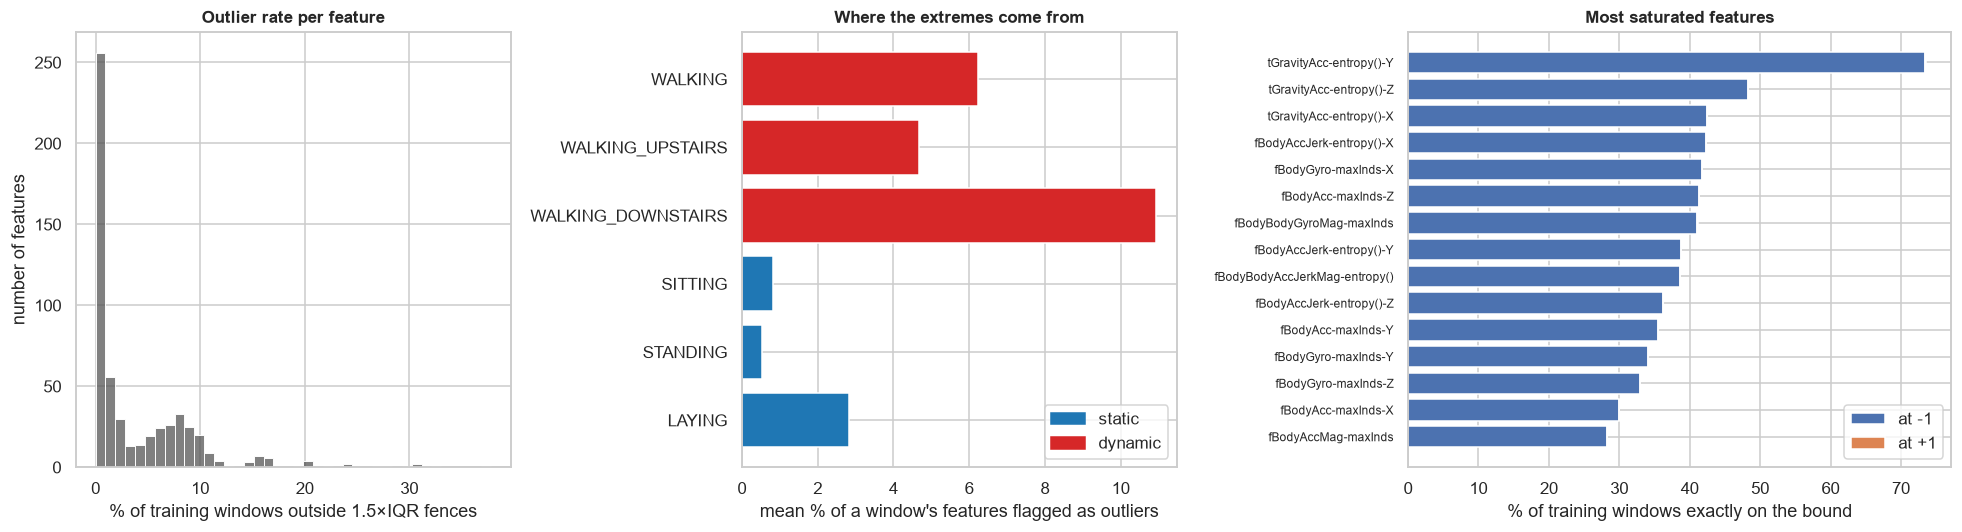

Features with the highest IQR-outlier rate:


,% at -1,% at +1,% IQR outliers,% |z|>3,group
tBodyAccJerk-mean()-X,0.01,0.01,37.79,2.42,t · Body acc jerk
tBodyGyro-mean()-X,0.00,0.00,32.22,2.11,t · Body gyro
tBodyGyroJerk-mean()-X,0.01,0.01,30.55,2.14,t · Body gyro jerk
tBodyAccJerk-mean()-Y,0.01,0.01,30.41,2.27,t · Body acc jerk
tBodyGyroJerk-mean()-Y,0.01,0.00,29.75,2.15,t · Body gyro jerk
tBodyAccJerk-mean()-Z,0.01,0.01,27.50,2.26,t · Body acc jerk
tBodyGyroJerk-mean()-Z,0.01,0.01,27.12,2.23,t · Body gyro jerk
tBodyGyro-mean()-Y,0.00,0.01,24.50,2.24,t · Body gyro


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), gridspec_kw={"width_ratios": [1, 1, 1.25]})

sns.histplot(out_rate * 100, bins=40, ax=axes[0], color="#555")
axes[0].set(xlabel="% of training windows outside 1.5×IQR fences", ylabel="number of features",
            title="Outlier rate per feature")

act_share = row_out_share.groupby(y_train).mean().reindex(ACTIVITY_ORDER) * 100
axes[1].barh(ACTIVITY_ORDER, act_share.values,
             color=[MOTION_COLORS["static" if a in STATIC else "dynamic"] for a in ACTIVITY_ORDER])
axes[1].invert_yaxis()
axes[1].set(xlabel="mean % of a window's features flagged as outliers", title="Where the extremes come from")
axes[1].legend(handles=[Patch(color=c, label=k) for k, c in MOTION_COLORS.items()], loc="lower right")

sat = extreme.assign(total=lambda d: d["% at -1"] + d["% at +1"]).nlargest(15, "total")
axes[2].barh(sat.index, sat["% at -1"], color="#4c72b0", label="at -1")
axes[2].barh(sat.index, sat["% at +1"], left=sat["% at -1"], color="#dd8452", label="at +1")
axes[2].invert_yaxis()
axes[2].tick_params(axis="y", labelsize=8)
axes[2].set(xlabel="% of training windows exactly on the bound", title="Most saturated features")
axes[2].legend(loc="lower right")
plt.tight_layout()
plt.show()

print("Features with the highest IQR-outlier rate:")
extreme.sort_values("% IQR outliers", ascending=False).head(8).round(2)

**Extreme values are real movement, not sensor errors**
* Every value lies in [−1, 1] and no feature has a zero IQR. 4 % of training cells fall outside the 1.5 × IQR fences, but only about 1 % have |z| > 3.
* **80 % of outlier cells come from dynamic windows**, even though they are only 45 % of the rows. Walking downstairs, the most vigorous activity, has about 11 % of a window's features flagged, against under 1 % for sitting or standing. The extremes are the movement signal itself, so removing or clipping them would delete information.
* The highest outlier rates (25–38 %) belong to the `mean()` of the jerk and gyroscope signals. These sit in a very narrow peak around a fixed value with long tails, so the IQR fences are tight. Section 6.2 shows these same features carry almost no activity information.
* **Saturation at −1** affects 21 features by more than 5 %, all of them `entropy` or `maxInds`. It is a floor effect with a physical cause. Example: `fBodyAcc-maxInds-X` is at −1 for 54 % of static windows and 0 % of dynamic ones, because with no movement the dominant frequency is the DC bin. Example: `fBodyAccJerk-entropy()-X` is at −1 for 76 % of static windows and 0 % of dynamic ones, because a still phone produces minimal spectral entropy. The pile-up at −1 is informative and should be kept.

## 3. Feature distributions and variance
### 3.1 Shape of the 561 distributions
For each feature (train split): mean, standard deviation, skewness, excess kurtosis and Sarle's bimodality coefficient, BC = (skew² + 1) / (excess kurtosis + 3(n−1)²/((n−2)(n−3))). BC above 5/9 ≈ 0.555 suggests a bimodal or multimodal distribution (strong skew can also push it up).

In [14]:
n = len(X_train)
shape = pd.DataFrame({"mean": X_train.mean(), "std": X_train.std(), "variance": X_train.var(),
                      "skewness": X_train.skew(), "excess kurtosis": X_train.kurt()})
shape["bimodality coef"] = (shape["skewness"] ** 2 + 1) / (
    shape["excess kurtosis"] + 3 * (n - 1) ** 2 / ((n - 2) * (n - 3)))
shape = shape.join(meta[["group", "domain", "statistic"]])

pd.Series({
    "|skewness| > 1": int((shape["skewness"].abs() > 1).sum()),
    "|skewness| > 2": int((shape["skewness"].abs() > 2).sum()),
    "right-skewed (skew > 1)": int((shape["skewness"] > 1).sum()),
    "left-skewed (skew < -1)": int((shape["skewness"] < -1).sum()),
    "excess kurtosis > 3 (heavy tails)": int((shape["excess kurtosis"] > 3).sum()),
    "bimodality coef > 0.555": int((shape["bimodality coef"] > 5 / 9).sum()),
}).to_frame("features (of 561)")

,features (of 561)
|skewness| > 1,277
|skewness| > 2,166
right-skewed (skew > 1),264
left-skewed (skew < -1),13
excess kurtosis > 3 (heavy tails),210
bimodality coef > 0.555,356


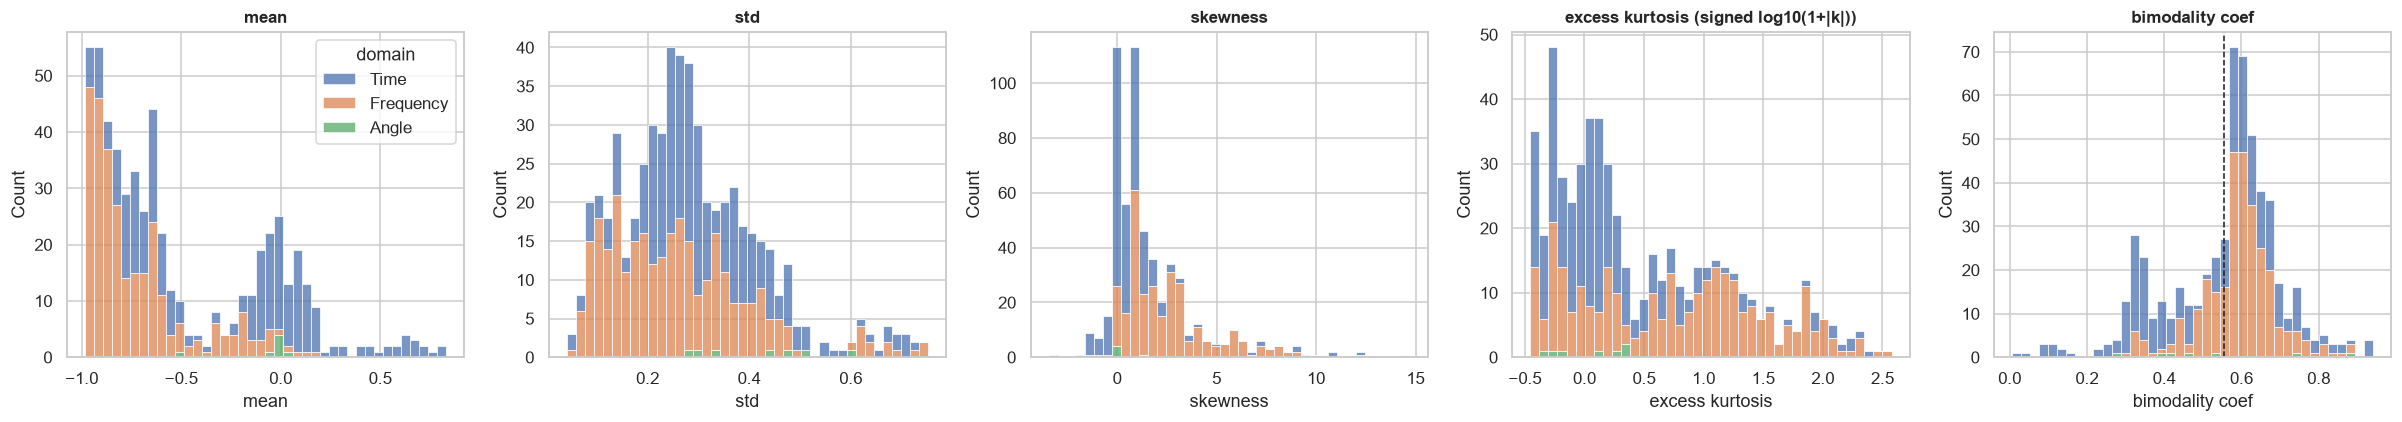

statistic,angle,arCoeff,meanFreq,correlation,entropy,mean,sma,skewness,mad,std,iqr,max,min,kurtosis,maxInds,energy,bandsEnergy
skewness,-0.02,-0.01,0.00,0.07,0.09,0.62,0.65,0.74,0.76,0.82,0.93,0.97,1.19,1.40,1.97,2.20,3.34
excess kurtosis,0.35,0.10,-0.07,-0.18,-1.68,0.66,-0.87,0.31,-0.42,-0.11,0.16,0.30,2.08,1.85,4.57,6.33,18.84
bimodality coef,0.47,0.34,0.35,0.37,0.76,0.58,0.66,0.50,0.63,0.62,0.61,0.61,0.60,0.61,0.60,0.58,0.58


In [15]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, col in zip(axes, ["mean", "std", "skewness", "excess kurtosis", "bimodality coef"]):
    data = shape.copy()
    if col == "excess kurtosis":
        data[col] = np.sign(data[col]) * np.log10(1 + data[col].abs())
    sns.histplot(data=data, x=col, hue="domain", multiple="stack", bins=40, ax=ax,
                 hue_order=["Time", "Frequency", "Angle"], legend=(col == "mean"))
    ax.set_title(col if col != "excess kurtosis" else "excess kurtosis (signed log10(1+|k|))")
axes[4].axvline(5 / 9, color="k", ls="--", lw=1)
plt.tight_layout()
plt.show()

shape.groupby("statistic")[["skewness", "excess kurtosis", "bimodality coef"]].median().sort_values("skewness").round(2).T

### 3.2 What typical features look like
Eight representative features, split by static (sitting, standing, laying) vs dynamic (walking variants) windows.

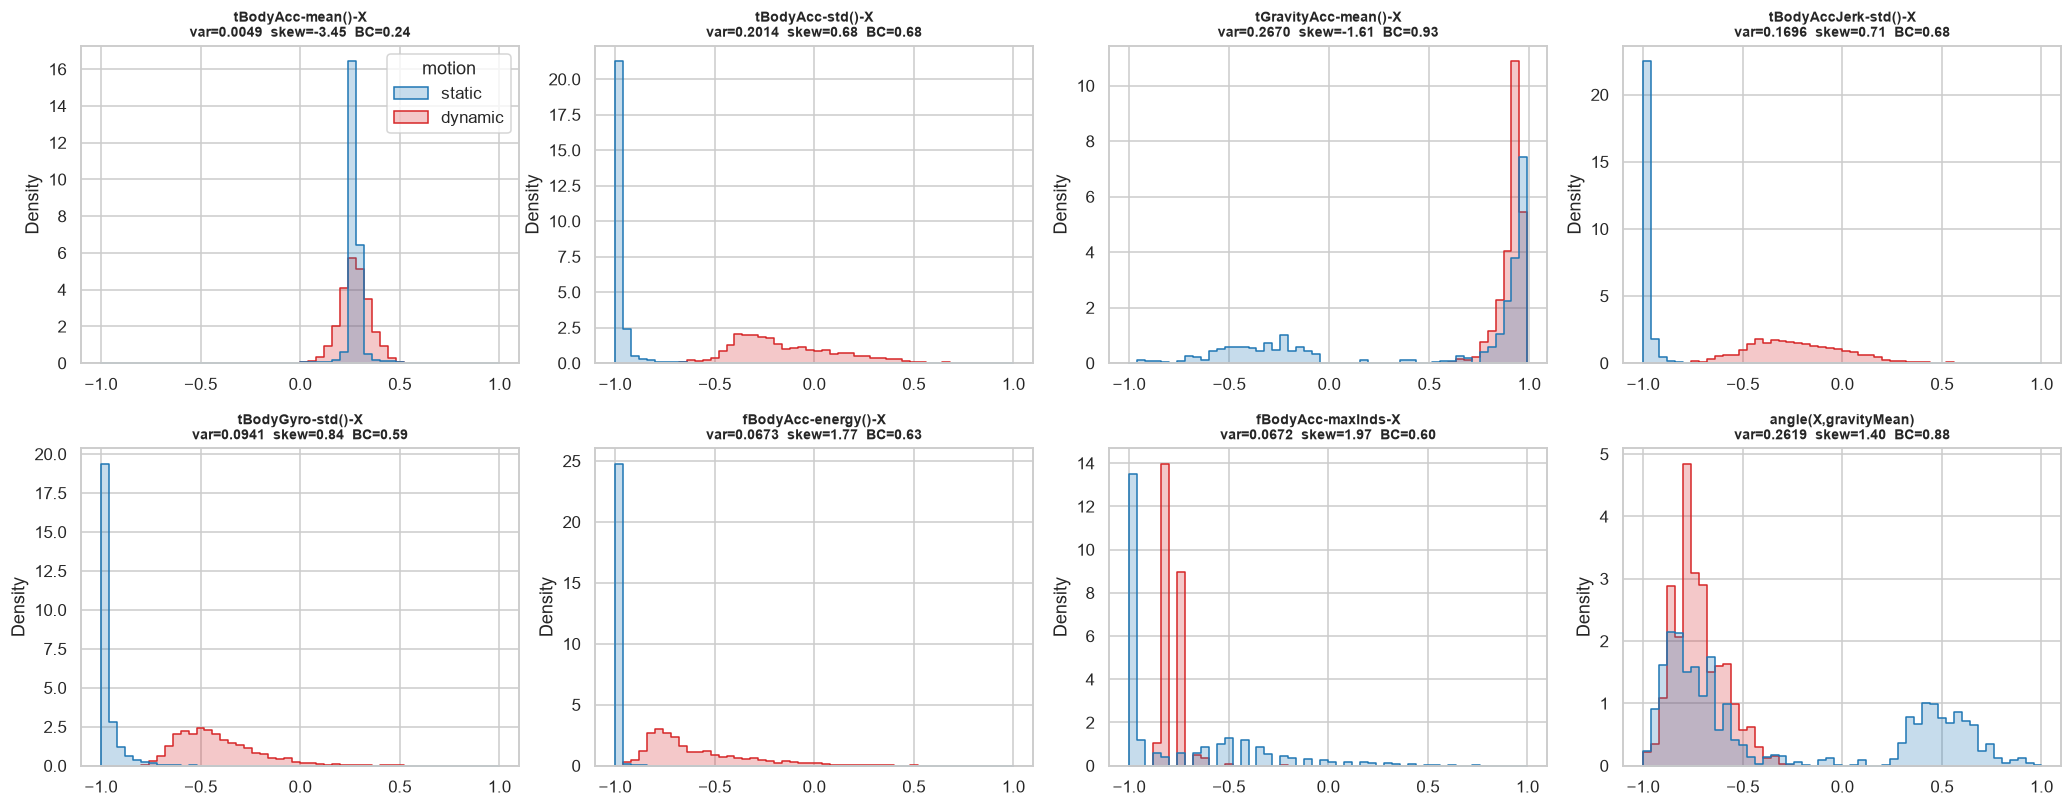

In [16]:
showcase = ["tBodyAcc-mean()-X", "tBodyAcc-std()-X", "tGravityAcc-mean()-X", "tBodyAccJerk-std()-X",
            "tBodyGyro-std()-X", "fBodyAcc-energy()-X", "fBodyAcc-maxInds-X", "angle(X,gravityMean)"]
fig, axes = plt.subplots(2, 4, figsize=(19, 7.5))
for ax, f in zip(axes.flat, showcase):
    sns.histplot(x=X_train[f], hue=motion_train, bins=50, stat="density", common_norm=False,
                 element="step", palette=MOTION_COLORS, ax=ax, legend=(f == showcase[0]))
    ax.set_title(f"{f}\nvar={shape.loc[f, 'variance']:.4f}  skew={shape.loc[f, 'skewness']:.2f}  "
                 f"BC={shape.loc[f, 'bimodality coef']:.2f}", fontsize=9)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

**Distributions are skewed and mostly bimodal**
* **Skew:** 277 of 561 features have |skew| > 1, and almost all of them (264) are skewed to the right. This is concentrated in the frequency domain (69 % of frequency features, against 28 % of time-domain features). `bandsEnergy` features are the most extreme, with median skew 3.3 and excess kurtosis 19; `energy` (2.2) and `maxInds` (2.0) follow.
* **Bimodality:** 356 features have a bimodality coefficient above 0.555. The panels above show why: most intensity-type features (`std`, `energy`, jerk, gyro) have a spike near −1 from static windows and a broad hump from dynamic windows. Orientation features such as `tGravityAcc-mean()-X` and `angle(X,gravityMean)` split along a different line, separating **laying** from upright postures.
* **Implication:** the features are mixtures rather than Gaussian. Models that assume within-class Gaussian inputs (LDA, Gaussian naive Bayes) may benefit from a power transform; tree ensembles, SVMs and k-NN do not need one.

### 3.3 Variance
The authors min–max scaled every feature into [−1, 1], so features share a **range** but not a **spread**. Variance is what decides how much each feature counts in distance-based and variance-based methods (k-NN, SVM with RBF kernel, k-means, PCA) if the data is used as delivered.

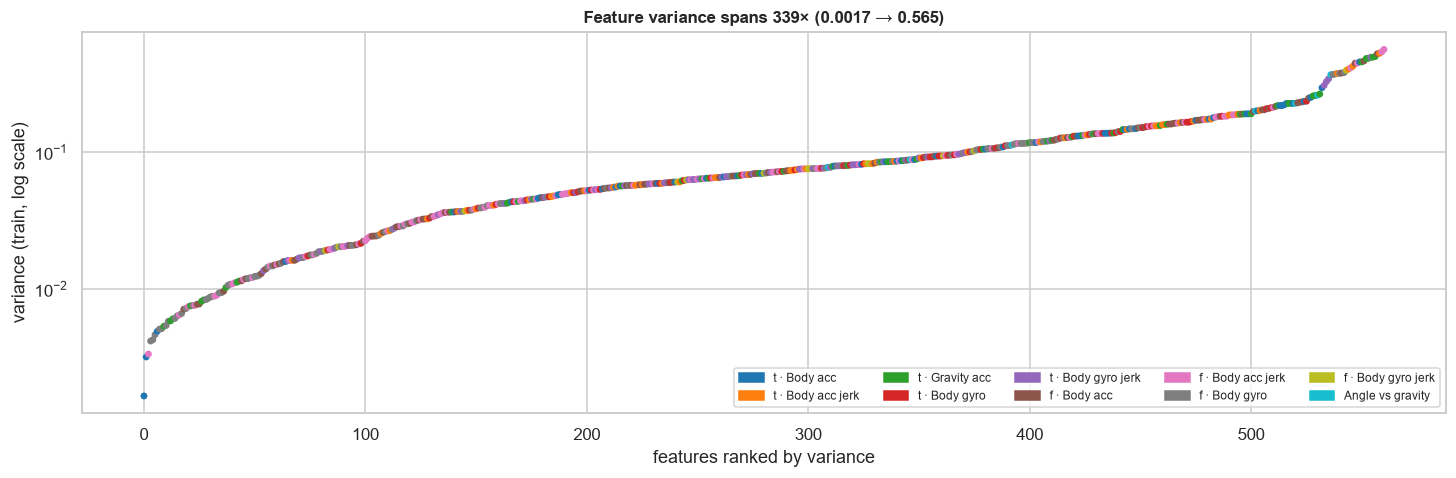

,lowest variance,variance,group,statistic,highest variance,variance,group,statistic
0,tBodyAcc-mean()-Y,0.0017,t · Body acc,mean,fBodyAccJerk-entropy()-X,0.5651,f · Body acc jerk,entropy
1,tBodyAcc-mean()-Z,0.0032,t · Body acc,mean,fBodyAccJerk-entropy()-Y,0.5425,f · Body acc jerk,entropy
2,"fBodyAccJerk-bandsEnergy()-57,64-X",0.0034,f · Body acc jerk,bandsEnergy,tBodyAccJerkMag-entropy(),0.5289,t · Body acc jerk,entropy
3,"fBodyGyro-bandsEnergy()-33,40-Y",0.0042,f · Body gyro,bandsEnergy,fBodyAcc-entropy()-X,0.5257,f · Body acc,entropy
4,"fBodyGyro-bandsEnergy()-33,40-Z",0.0043,f · Body gyro,bandsEnergy,"tGravityAcc-correlation()-X,Z",0.5009,t · Gravity acc,correlation
5,"fBodyGyro-bandsEnergy()-33,48-Z",0.0047,f · Body gyro,bandsEnergy,"tGravityAcc-correlation()-Y,Z",0.4958,t · Gravity acc,correlation
6,tBodyAcc-mean()-X,0.0049,t · Body acc,mean,tBodyGyroJerkMag-entropy(),0.4952,t · Body gyro jerk,entropy
7,"fBodyGyro-bandsEnergy()-33,48-Y",0.0051,f · Body gyro,bandsEnergy,tGravityAcc-energy()-X,0.4871,t · Gravity acc,energy


statistic,bandsEnergy,energy,arCoeff,maxInds,min,meanFreq,max,iqr,skewness,kurtosis,mean,correlation,std,mad,sma,angle,entropy
median variance by statistic,0.0209,0.0481,0.0591,0.0607,0.0632,0.0714,0.0959,0.1057,0.108,0.1161,0.1206,0.1319,0.1379,0.1468,0.1663,0.201,0.3781


In [17]:
var_sorted = shape["variance"].sort_values()
fig, ax = plt.subplots(figsize=(16, 4.5))
ax.scatter(np.arange(len(var_sorted)), var_sorted.values, s=12,
           c=[GROUP_COLORS[g] for g in group_of[var_sorted.index]])
ax.set_yscale("log")
ax.set(xlabel="features ranked by variance", ylabel="variance (train, log scale)",
       title=f"Feature variance spans {var_sorted.iloc[-1] / var_sorted.iloc[0]:.0f}× "
             f"({var_sorted.iloc[0]:.4f} → {var_sorted.iloc[-1]:.3f})")
ax.legend(handles=[Patch(color=GROUP_COLORS[g], label=g) for g in GROUP_ORDER], ncol=5, fontsize=8, loc="lower right")
plt.show()

low_high = pd.concat([shape.nsmallest(8, "variance")[["variance", "group", "statistic"]].reset_index(names="lowest variance"),
                      shape.nlargest(8, "variance")[["variance", "group", "statistic"]].reset_index(names="highest variance")],
                     axis=1)
display(low_high)
shape.groupby("statistic")["variance"].median().sort_values().round(4).to_frame("median variance by statistic").T

**Variance differs by a factor of 339 even though the range is fixed**
* The **lowest-variance** features are `tBodyAcc-mean()` X/Y/Z (σ ≈ 0.04–0.07) and the highest-frequency `bandsEnergy` bins (57–64 and 33–48). Both are close to constant by construction. Body acceleration is gravity-filtered, so its window mean is ≈ 0, and the energy above about 12 Hz (FFT bins 33–64) is tiny for human movement.
* The **highest-variance** features are `entropy` features plus the gravity `correlation`/`energy` features (σ ≈ 0.7–0.75), all of which flip between static and dynamic levels.
* Ordered by statistic, median variance rises from `bandsEnergy` (0.021) to `entropy` (0.378). On the raw scale, a Euclidean distance is therefore weighted toward entropy-type features and away from band energies. Section 6 quantifies this.

## 4. Correlation and redundancy
Pearson correlations between all 561 features on the training split (157,080 distinct pairs).

In [18]:
corr = X_train.corr()
abs_corr = corr.abs()
A = abs_corr.to_numpy().copy()
np.fill_diagonal(A, np.nan)
max_abs_r = pd.Series(np.nanmax(A, axis=1), index=feature_names)
pair_r = abs_corr.to_numpy()[np.triu_indices(len(feature_names), k=1)]

thresholds = [0.8, 0.9, 0.95, 0.99, 0.999]
pd.DataFrame({
    "pairs with |r| ≥ t": [int((pair_r >= t).sum()) for t in thresholds],
    "% of all pairs": [round((pair_r >= t).mean() * 100, 2) for t in thresholds],
    "features with ≥1 such partner": [int((max_abs_r >= t).sum()) for t in thresholds],
}, index=pd.Index(thresholds, name="threshold t"))

,pairs with |r| ≥ t,% of all pairs,features with ≥1 such partner
threshold t,,,
0.800,23058,14.68,456
0.900,8206,5.22,431
0.950,2281,1.45,391
0.990,207,0.13,183
0.999,42,0.03,60


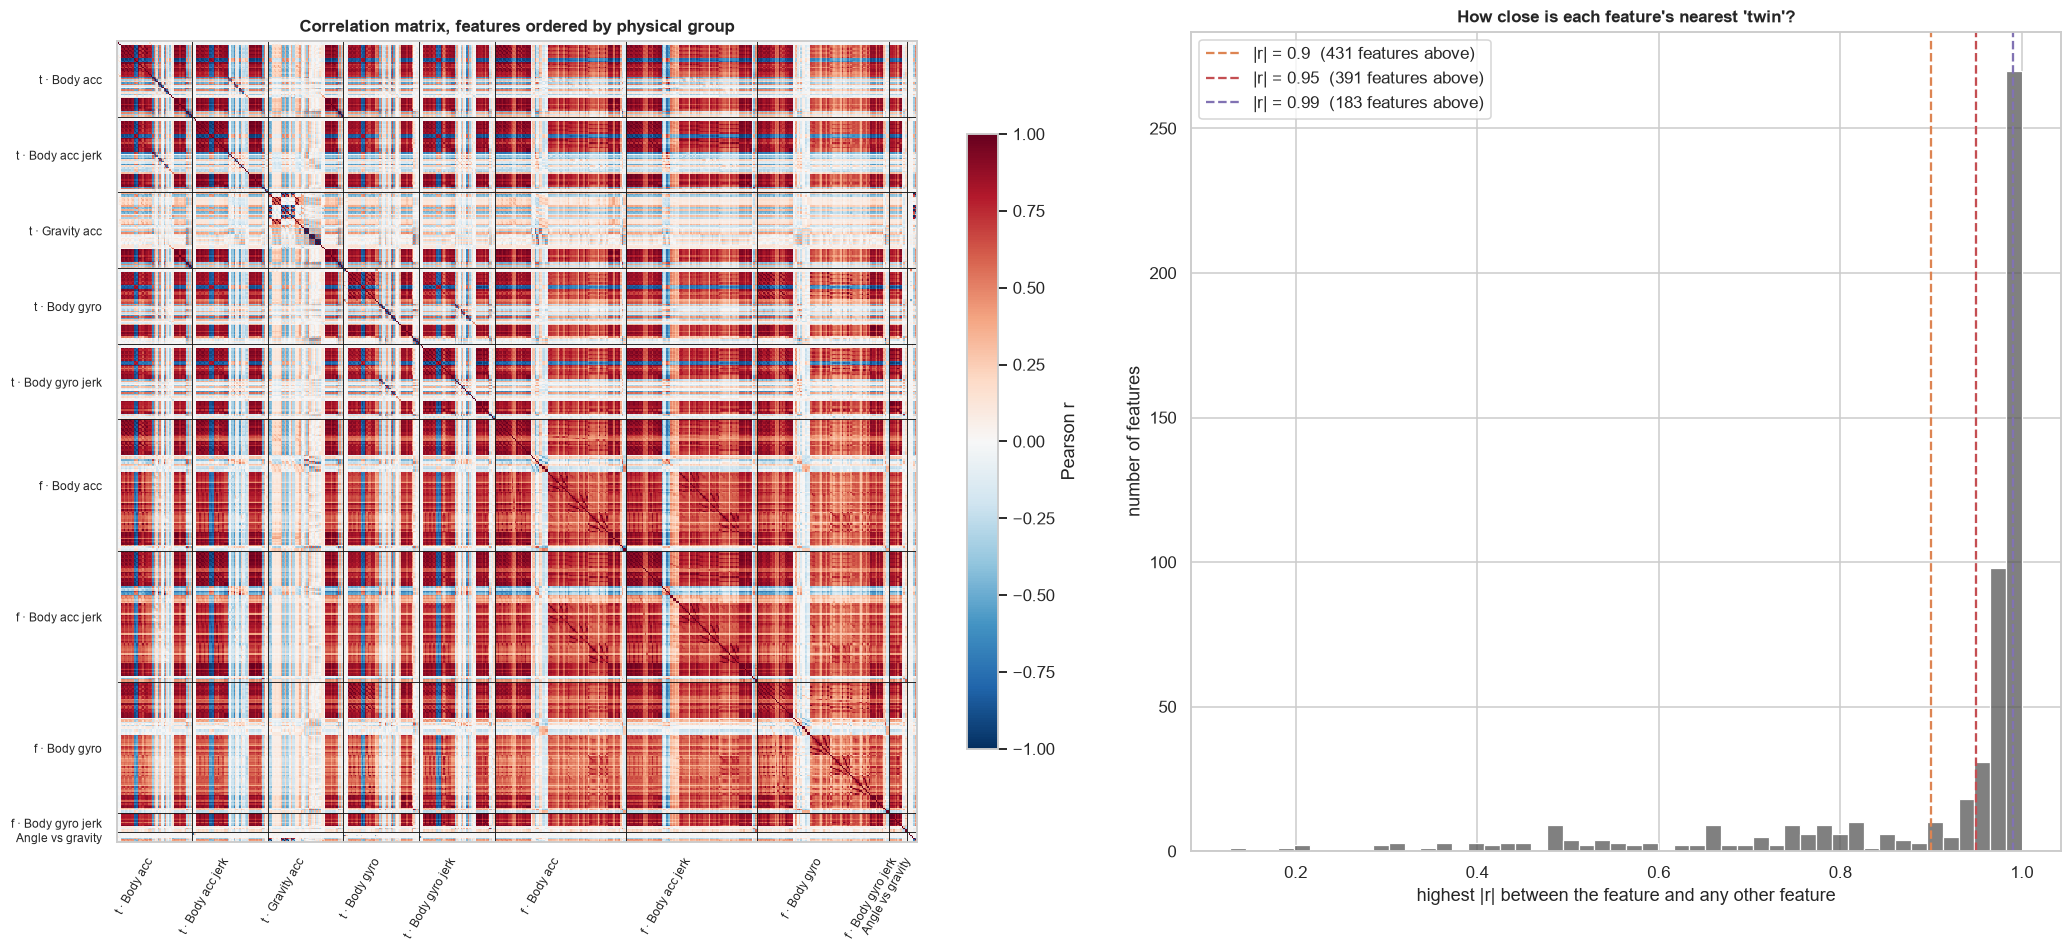

In [19]:
order = meta.sort_values(["group", "col"]).index
C = corr.loc[order, order].to_numpy()
ends = meta["group"].value_counts(sort=False).reindex(GROUP_ORDER).cumsum().to_numpy()
starts = np.r_[0, ends[:-1]]

fig, axes = plt.subplots(1, 2, figsize=(19, 8.5), gridspec_kw={"width_ratios": [1.15, 1]})
im = axes[0].imshow(C, cmap="RdBu_r", vmin=-1, vmax=1, interpolation="nearest")
for b in ends[:-1]:
    axes[0].axhline(b - 0.5, color="k", lw=0.6)
    axes[0].axvline(b - 0.5, color="k", lw=0.6)
mids = (starts + ends) / 2
axes[0].set_xticks(mids, GROUP_ORDER, rotation=60, ha="right", fontsize=8)
axes[0].set_yticks(mids, GROUP_ORDER, fontsize=8)
axes[0].grid(False)
axes[0].set_title("Correlation matrix, features ordered by physical group")
fig.colorbar(im, ax=axes[0], shrink=0.75, label="Pearson r")

sns.histplot(max_abs_r, bins=50, ax=axes[1], color="#555")
for t, c in [(0.9, "#dd8452"), (0.95, "#c44e52"), (0.99, "#8172b3")]:
    axes[1].axvline(t, ls="--", color=c, label=f"|r| = {t}  ({(max_abs_r >= t).sum()} features above)")
axes[1].set(xlabel="highest |r| between the feature and any other feature", ylabel="number of features",
            title="How close is each feature's nearest 'twin'?")
axes[1].legend(loc="upper left")
plt.tight_layout()
plt.show()

### 4.1 Where the redundancy sits
Left: mean |r| within and between physical groups. Right: mean |r| between different summary statistics computed on the **same** signal and axis (e.g. `tBodyAcc-std()-X` vs `tBodyAcc-mad()-X`).

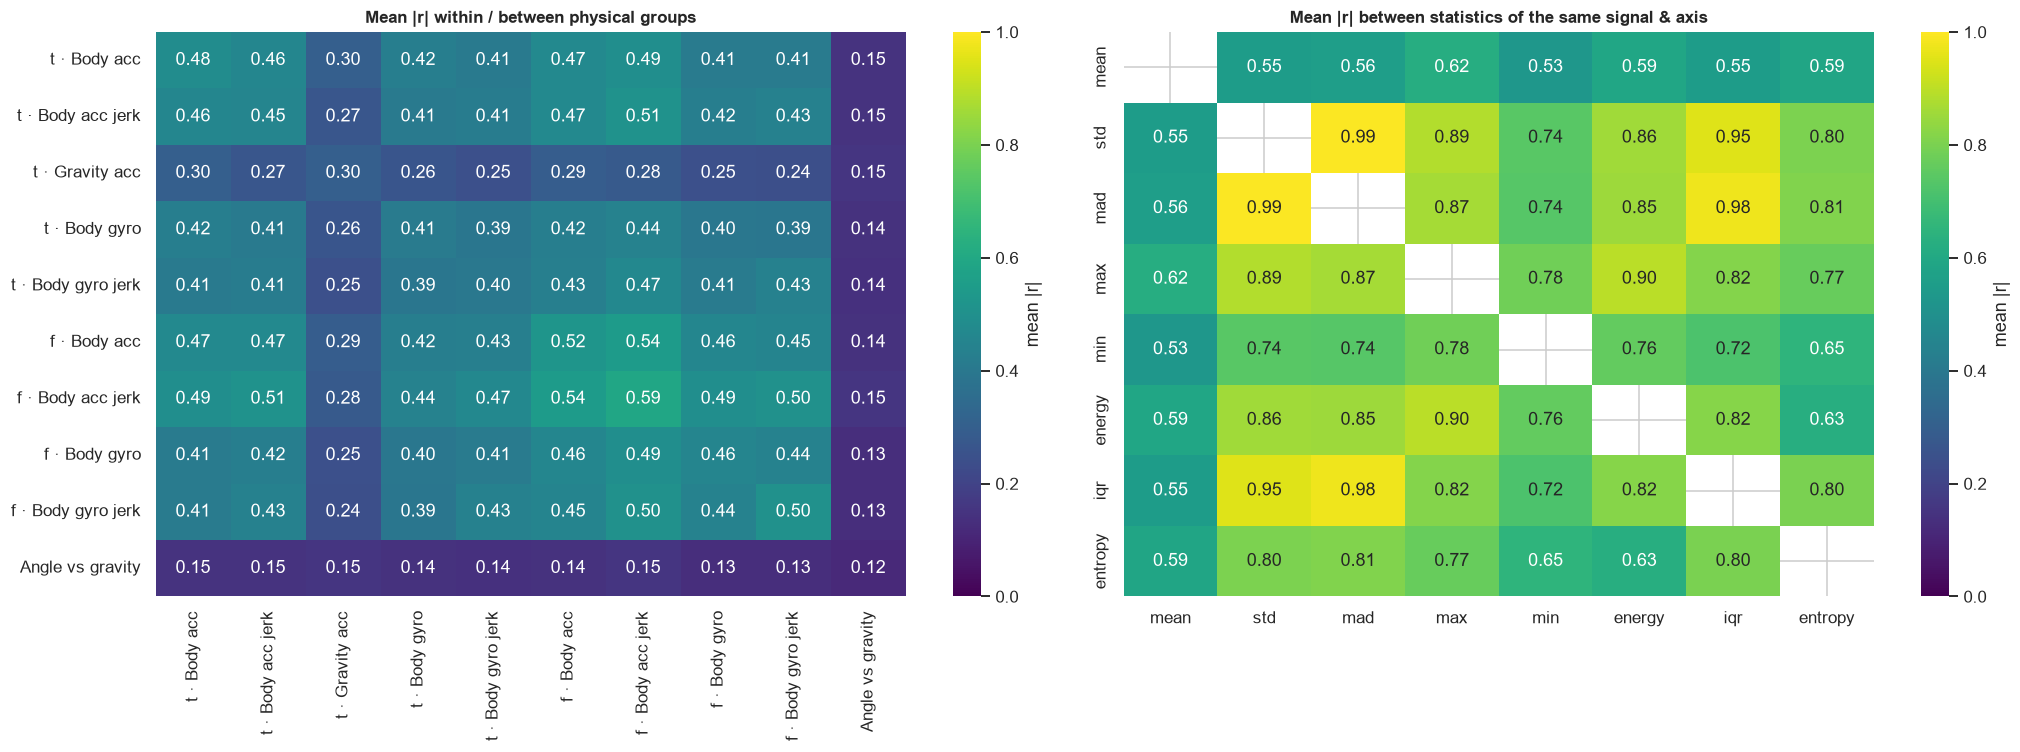

In [20]:
block = pd.DataFrame(index=GROUP_ORDER, columns=GROUP_ORDER, dtype=float)
idx_of = {g: np.where(group_of == g)[0] for g in GROUP_ORDER}
for gi in GROUP_ORDER:
    for gj in GROUP_ORDER:
        block.loc[gi, gj] = np.nanmean(A[np.ix_(idx_of[gi], idx_of[gj])])

STAT_SUBSET = ["mean", "std", "mad", "max", "min", "energy", "iqr", "entropy"]
m = meta[meta["statistic"].isin(STAT_SUBSET)].copy()
m["signal_key"] = m["signal"] + "|" + m["axis"].fillna("")
records = []
for _, idx in m.groupby("signal_key").groups.items():
    idx = list(idx)
    for i, a in enumerate(idx):
        for b in idx[i + 1:]:
            sa, sb = m.at[a, "statistic"], m.at[b, "statistic"]
            records += [(sa, sb, abs_corr.at[a, b]), (sb, sa, abs_corr.at[a, b])]
stat_r = (pd.DataFrame(records, columns=["a", "b", "r"]).pivot_table(index="a", columns="b", values="r", aggfunc="mean")
          .reindex(index=STAT_SUBSET, columns=STAT_SUBSET))

fig, axes = plt.subplots(1, 2, figsize=(19, 7))
sns.heatmap(block, annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1, ax=axes[0], cbar_kws={"label": "mean |r|"})
axes[0].set_title("Mean |r| within / between physical groups")
sns.heatmap(stat_r, annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1, ax=axes[1], cbar_kws={"label": "mean |r|"})
axes[1].set(title="Mean |r| between statistics of the same signal & axis", xlabel="", ylabel="")
plt.tight_layout()
plt.show()

In [21]:
# Strongest pairs once the exact duplicates (r = 1) are set aside
A_dedup = abs_corr.loc[keep_dedup, keep_dedup].to_numpy()
iu = np.triu_indices(len(keep_dedup), k=1)
top = np.argsort(A_dedup[iu])[::-1][:12]
pd.DataFrame({"feature A": [keep_dedup[i] for i in iu[0][top]],
              "feature B": [keep_dedup[j] for j in iu[1][top]],
              "r": [corr.at[keep_dedup[i], keep_dedup[j]] for i, j in zip(iu[0][top], iu[1][top])]})

,feature A,feature B,r
0,tBodyAccJerk-energy()-Z,fBodyAccJerk-energy()-Z,1.0000
1,tBodyAccJerk-energy()-Y,fBodyAccJerk-energy()-Y,1.0000
2,tBodyAccJerk-energy()-X,fBodyAccJerk-energy()-X,1.0000
3,fBodyAcc-energy()-X,"fBodyAcc-bandsEnergy()-1,24-X",0.9999
4,fBodyGyro-energy()-X,"fBodyGyro-bandsEnergy()-1,24-X",0.9998
5,fBodyAcc-energy()-Y,"fBodyAcc-bandsEnergy()-1,24-Y",0.9997
6,tBodyAccJerk-sma(),tBodyAccJerkMag-mean(),0.9997
7,tBodyAcc-energy()-X,fBodyAcc-energy()-X,0.9996
8,fBodyGyro-energy()-Z,"fBodyGyro-bandsEnergy()-1,24-Z",0.9995
9,tBodyAcc-energy()-X,"fBodyAcc-bandsEnergy()-1,24-X",0.9995


### 4.2 How many features are really distinct?
Two complementary counts at each correlation threshold *t*:
* **Greedy filter** — walk the features in file order and keep one only if its |r| with every feature already kept is ≤ *t*. This is the simple, reproducible filter recommended for preprocessing.
* **Complete-linkage clusters** — cluster on distance 1 − |r| and cut so that every pair inside a cluster has |r| ≥ *t*. The number of clusters is the number of "information units" at that threshold.

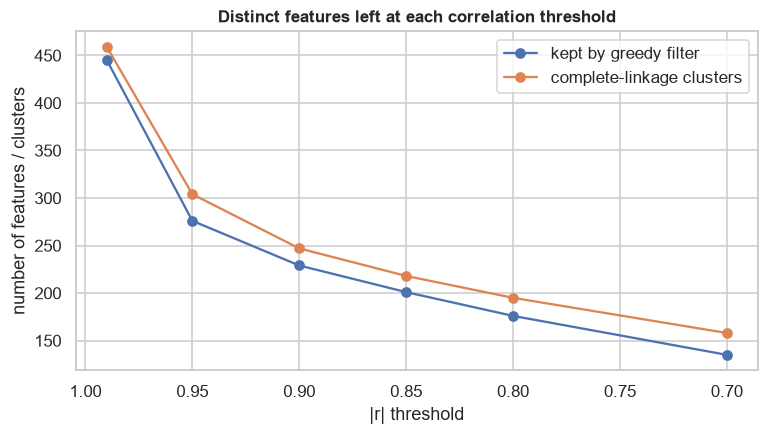

,kept by greedy filter,complete-linkage clusters,% of 561 kept (greedy)
|r| threshold,,,
0.99,445,459,79.3
0.95,276,304,49.2
0.90,229,247,40.8
0.85,201,218,35.8
0.80,176,195,31.4
0.70,135,158,24.1


In [22]:
def correlation_filter(abs_corr: pd.DataFrame, threshold: float) -> list:
    """Keep a feature only if its |r| with every already-kept feature is <= threshold (file order)."""
    M = abs_corr.to_numpy()
    kept = []
    for j in range(M.shape[0]):
        if not kept or M[j, kept].max() <= threshold:
            kept.append(j)
    return list(abs_corr.columns[kept])


D = 1 - abs_corr.to_numpy()
D = np.clip((D + D.T) / 2, 0, None)
np.fill_diagonal(D, 0)
Z_link = linkage(squareform(D, checks=False), method="complete")

grid = [0.99, 0.95, 0.9, 0.85, 0.8, 0.7]
filtered = {t: correlation_filter(abs_corr, t) for t in grid}
redundancy = pd.DataFrame({
    "kept by greedy filter": [len(filtered[t]) for t in grid],
    "complete-linkage clusters": [len(np.unique(fcluster(Z_link, t=1 - t, criterion="distance"))) for t in grid],
}, index=pd.Index(grid, name="|r| threshold"))
redundancy["% of 561 kept (greedy)"] = (redundancy["kept by greedy filter"] / 561 * 100).round(1)
kept_095 = filtered[0.95]
assert not set(kept_095) & set(exact_drop), "exact duplicates should never survive the filter"

fig, ax = plt.subplots(figsize=(8, 4))
redundancy[["kept by greedy filter", "complete-linkage clusters"]].plot(marker="o", ax=ax)
ax.invert_xaxis()
ax.set(ylabel="number of features / clusters", title="Distinct features left at each correlation threshold")
plt.show()
redundancy

**Redundancy is the defining property of this feature set**
* **2,281 pairs** have |r| ≥ 0.95, and **391 of 561 features (70 %)** have at least one near-twin at that level (183 at ≥ 0.99).
* A greedy filter at |r| > 0.95 keeps **276 features (49 %)**. Complete-linkage clustering gives a similar picture (304 clusters in which every pair has |r| ≥ 0.95). Even at 0.8, 176 features remain distinct, so the set compresses heavily but not down to a handful of features.
* **Which statistics overlap:** `std`, `mad` and `iqr` of the same signal and axis correlate at 0.95–0.99. They are three estimates of the same spread. `max` and `energy` follow at 0.86–0.90. `mean` is the most independent statistic (≈ 0.55).
* **Strongest non-identical pairs** have a physical explanation:
  * Time-domain and frequency-domain `energy` of the same signal correlate at r ≈ 1.000. This is **Parseval's theorem**: a signal's energy is the same in both domains.
  * `energy()` and `bandsEnergy()-1,24` agree at r ≈ 0.9999, because almost all movement energy sits in the lowest frequency bins.
  * `tBodyAccJerk-sma()` and `tBodyAccJerkMag-mean()` (r ≈ 0.9997) both measure average jerk magnitude.
* **Between groups:** all body-motion groups (acc, gyro, jerk; time and frequency) inter-correlate at 0.4–0.6 because they all track *how much the person is moving*. Gravity (≈ 0.25–0.30) and angle (≈ 0.15) features are the least correlated with the rest; they carry **orientation/posture** information that the motion groups do not.

## 5. Features grouped by physical meaning
### 5.1 Composition
The six physical categories in the brief overlap — one feature can be accelerometer + jerk + frequency domain at once — so the first table counts membership, not a partition. The ten groups used elsewhere in the notebook *are* a partition.

In [23]:
categories = {
    "Acceleration (accelerometer, body + gravity)": meta["sensor"].eq("accelerometer") & ~meta["domain"].eq("Angle"),
    "Gyroscope (angular velocity)": meta["sensor"].eq("gyroscope"),
    "Gravity component": meta["component"].eq("gravity"),
    "Jerk (time derivative)": meta["jerk"] & ~meta["domain"].eq("Angle"),
    "Time domain": meta["domain"].eq("Time"),
    "Frequency domain": meta["domain"].eq("Frequency"),
    "Magnitude (Euclidean norm of X, Y, Z)": meta["magnitude"],
    "Angle between vectors": meta["domain"].eq("Angle"),
}
cat_table = pd.DataFrame({
    "features": {k: int(v.sum()) for k, v in categories.items()},
    "exact duplicates among them": {k: int(v[exact_drop].sum()) for k, v in categories.items()},
    "kept by |r|>0.95 filter": {k: int(v[kept_095].sum()) for k, v in categories.items()},
})
cat_table["% of 561"] = (cat_table["features"] / 561 * 100).round(1)
cat_table

,features,exact duplicates among them,kept by |r|>0.95 filter,% of 561
"Acceleration (accelerometer, body + gravity)",343,17,160,61.1
Gyroscope (angular velocity),211,4,112,37.6
Gravity component,53,13,20,9.4
Jerk (time derivative),211,4,93,37.6
Time domain,265,17,149,47.2
Frequency domain,289,4,123,51.5
"Magnitude (Euclidean norm of X, Y, Z)",117,21,46,20.9
Angle between vectors,7,0,4,1.2


In [24]:
pd.crosstab(meta["group"], meta["statistic"], margins=True, margins_name="total")

statistic,angle,arCoeff,bandsEnergy,correlation,energy,entropy,iqr,kurtosis,mad,max,maxInds,mean,meanFreq,min,skewness,sma,std,total
group,,,,,,,,,,,,,,,,,,
t · Body acc,0,16,0,3,4,4,4,0,4,4,0,4,0,4,0,2,4,53
t · Body acc jerk,0,16,0,3,4,4,4,0,4,4,0,4,0,4,0,2,4,53
t · Gravity acc,0,16,0,3,4,4,4,0,4,4,0,4,0,4,0,2,4,53
t · Body gyro,0,16,0,3,4,4,4,0,4,4,0,4,0,4,0,2,4,53
t · Body gyro jerk,0,16,0,3,4,4,4,0,4,4,0,4,0,4,0,2,4,53
f · Body acc,0,0,42,0,4,4,4,4,4,4,4,4,4,4,4,2,4,92
f · Body acc jerk,0,0,42,0,4,4,4,4,4,4,4,4,4,4,4,2,4,92
f · Body gyro,0,0,42,0,4,4,4,4,4,4,4,4,4,4,4,2,4,92
f · Body gyro jerk,0,0,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,13


### 5.2 Group profiles
One row per physical group: size, spread, shape, redundancy and how much survives de-duplication and the |r| > 0.95 filter.

In [25]:
g = meta["group"]
profile = pd.DataFrame({
    "features": g.value_counts(sort=False),
    "exact duplicates": pd.Series(meta.index.isin(exact_drop), index=meta.index).groupby(g, observed=True).sum(),
    "median variance": shape["variance"].groupby(g, observed=True).median(),
    "median |skew|": shape["skewness"].abs().groupby(g, observed=True).median(),
    "mean |r| within group": pd.Series(np.diag(block.to_numpy()), index=GROUP_ORDER),
    "% with a |r|>0.95 twin": (max_abs_r > 0.95).groupby(g, observed=True).mean() * 100,
    "kept by |r|>0.95 filter": pd.Series(meta.index.isin(kept_095), index=meta.index).groupby(g, observed=True).sum(),
}).reindex(GROUP_ORDER)
profile["% kept"] = profile["kept by |r|>0.95 filter"] / profile["features"] * 100
profile.loc["All features"] = [561, len(exact_drop), shape["variance"].median(), shape["skewness"].abs().median(),
                               np.nanmean(A), (max_abs_r > 0.95).mean() * 100, len(kept_095), len(kept_095) / 561 * 100]
profile.round(3)

,features,exact duplicates,median variance,median |skew|,mean |r| within group,% with a |r|>0.95 twin,kept by |r|>0.95 filter,% kept
t · Body acc,53.0,1.0,0.094,0.431,0.482,62.264,34.0,64.151
t · Body acc jerk,53.0,1.0,0.076,0.613,0.455,62.264,30.0,56.604
t · Gravity acc,53.0,13.0,0.087,0.676,0.299,83.019,20.0,37.736
t · Body gyro,53.0,1.0,0.093,0.533,0.412,45.283,39.0,73.585
t · Body gyro jerk,53.0,1.0,0.066,0.917,0.401,58.491,26.0,49.057
f · Body acc,92.0,1.0,0.067,1.811,0.520,81.522,44.0,47.826
f · Body acc jerk,92.0,1.0,0.050,1.903,0.591,72.826,32.0,34.783
f · Body gyro,92.0,1.0,0.040,2.923,0.456,77.174,42.0,45.652
f · Body gyro jerk,13.0,1.0,0.076,1.609,0.503,76.923,5.0,38.462
Angle vs gravity,7.0,0.0,0.201,0.082,0.116,42.857,4.0,57.143


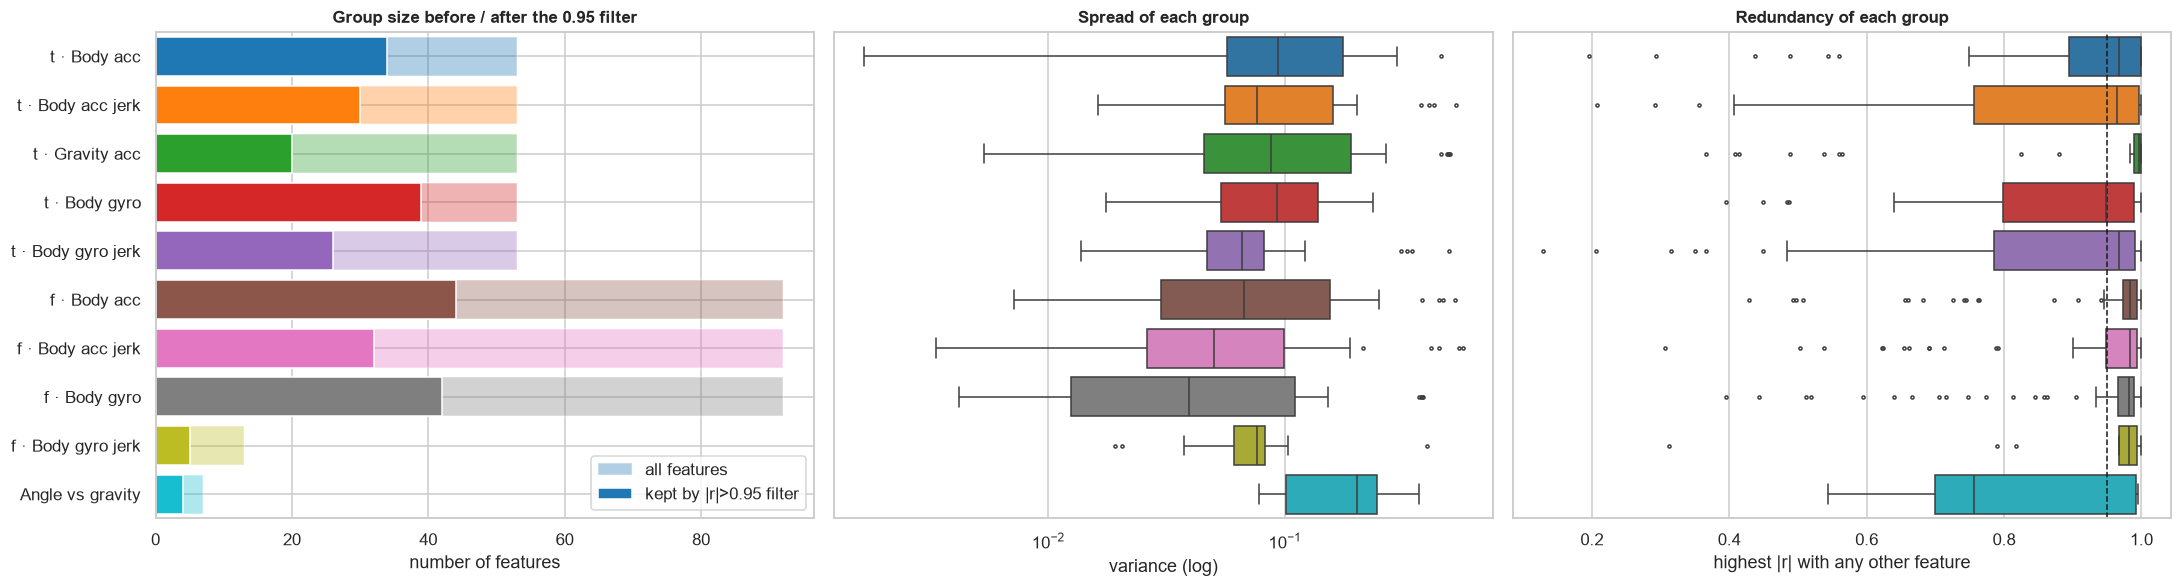

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5), sharey=True)
y_pos = np.arange(len(GROUP_ORDER))
cols = [GROUP_COLORS[gname] for gname in GROUP_ORDER]

axes[0].barh(y_pos, profile.loc[GROUP_ORDER, "features"], color=cols, alpha=0.35, label="all features")
axes[0].barh(y_pos, profile.loc[GROUP_ORDER, "kept by |r|>0.95 filter"], color=cols, label="kept by |r|>0.95 filter")
axes[0].set_yticks(y_pos, GROUP_ORDER)
axes[0].invert_yaxis()
axes[0].set(xlabel="number of features", title="Group size before / after the 0.95 filter")
axes[0].legend(loc="lower right")

plot_df = shape.assign(group=group_of, max_abs_r=max_abs_r)
sns.boxplot(data=plot_df, y="group", x="variance", order=GROUP_ORDER, palette=GROUP_COLORS, ax=axes[1], fliersize=2)
axes[1].set(xscale="log", xlabel="variance (log)", ylabel="", title="Spread of each group")

sns.boxplot(data=plot_df, y="group", x="max_abs_r", order=GROUP_ORDER, palette=GROUP_COLORS, ax=axes[2], fliersize=2)
axes[2].axvline(0.95, ls="--", color="k", lw=1)
axes[2].set(xlabel="highest |r| with any other feature", ylabel="", title="Redundancy of each group")
plt.tight_layout()
plt.show()

**What the physical grouping shows**
* **Composition:** 61 % of features come from the accelerometer and 38 % from the gyroscope. Time (265) and frequency (289) are roughly balanced, while the angle features are only 7. Only three body signals have full frequency-domain versions (92 features each), and gyro jerk has only a magnitude version (13). The frequency domain therefore leans on body acceleration, acceleration jerk and gyroscope.
* **Gravity is the most redundant group:** 13 of its 53 features are exact copies (the `tGravityAccMag` bug), 83 % have a near-twin, and only 20 (38 %) survive the 0.95 filter. Gravity is a slowly varying 3-D vector, so its many summary statistics say nearly the same thing.
* **Frequency body groups come next:** 73–82 % have a near-twin and 35–48 % are kept. Most of the overlap is between the 42 `bandsEnergy` features and `energy` in each group.
* **Time-domain gyroscope is the least redundant motion group** (74 % kept). The angle features have low within-group correlation (0.12) and high variance, but 4 of the 7 are near-useless (§6.2).
* **Skew follows domain:** frequency groups have median |skew| of 1.6–2.9, against 0.4–0.9 for time groups.

## 6. Effect of standardisation and duplicate-feature removal
`StandardScaler` is fitted on the training split only and then applied to both splits. Four configurations are compared:

| Configuration | Features | What it does |
|---|---|---|
| Raw | 561 | data as delivered (min–max scaled to [−1, 1] by the authors) |
| Standardised | 561 | every feature centred to mean 0, scaled to standard deviation 1 |
| Standardised + exact duplicates removed | 540 | as above, minus the 21 value-identical copies |
| Standardised + \|r\| > 0.95 filter | see §4.2 | as above, minus near-duplicates |

In [27]:
scaler = StandardScaler().fit(X_train)
Xs_train = pd.DataFrame(scaler.transform(X_train), columns=feature_names, index=X_train.index)
Xs_test = pd.DataFrame(scaler.transform(X_test), columns=feature_names, index=X_test.index)

print("Correlation unchanged by standardisation:",
      bool(np.allclose(Xs_train.corr().to_numpy(), corr.to_numpy(), atol=1e-10)))
print("Shape and order unchanged (skewness identical):",
      bool(np.allclose(Xs_train.skew().to_numpy(), shape["skewness"].to_numpy(), atol=1e-8)))

Correlation unchanged by standardisation: True
Shape and order unchanged (skewness identical): True


### 6.1 Feature distributions before and after
Three of the lowest-variance, three median-variance and three of the highest-variance features. Standardisation is a linear rescaling, so each distribution keeps its shape but every feature now occupies the same spread.

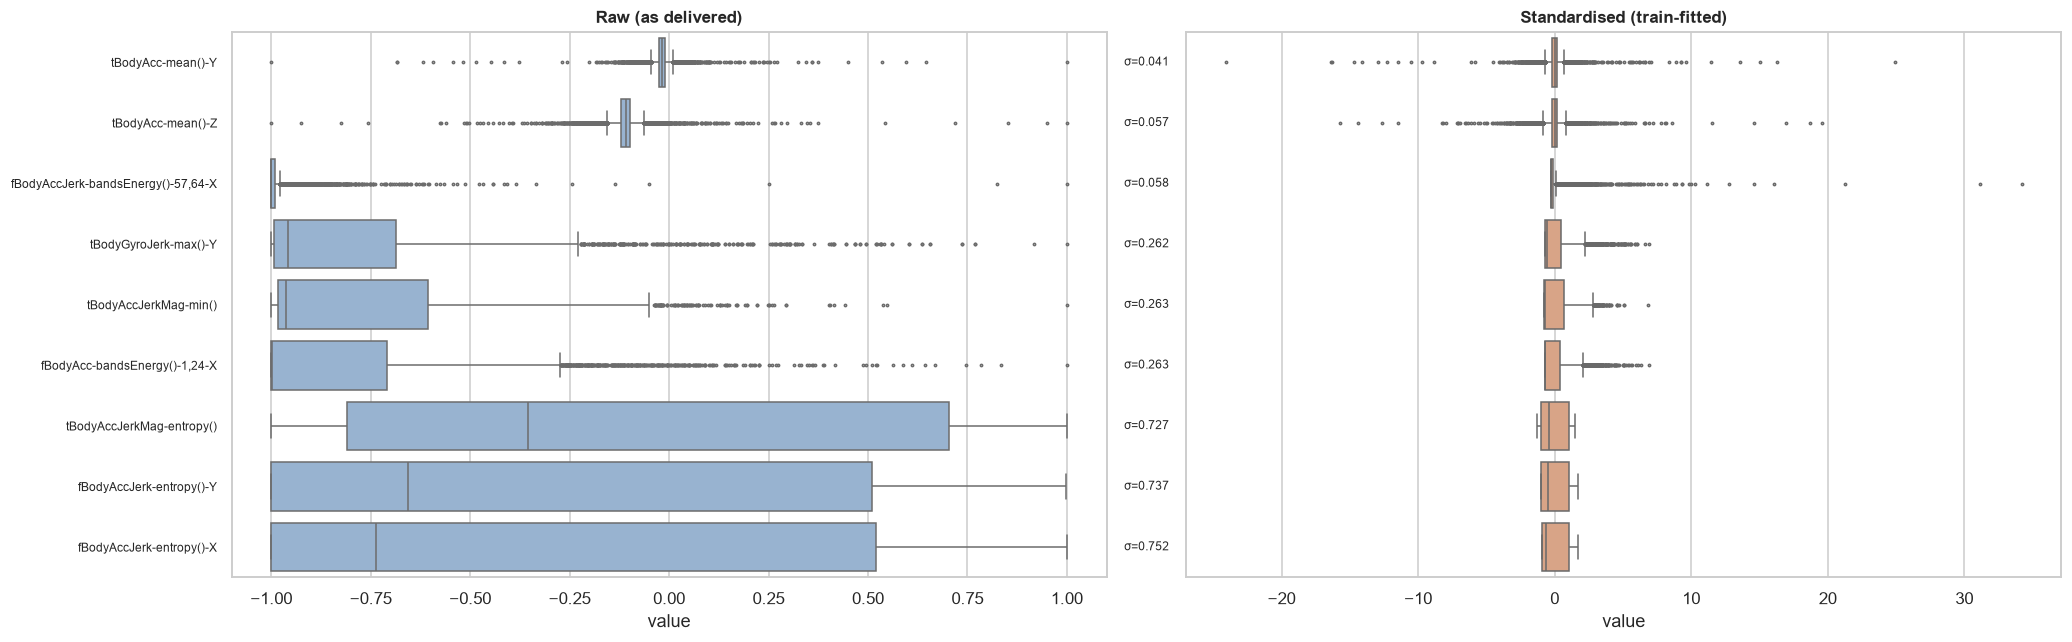

In [28]:
v = shape.loc[keep_dedup, "variance"].sort_values()      # skip value-identical copies
picked = list(v.index[:3]) + list(v.index[len(v) // 2 - 1: len(v) // 2 + 2]) + list(v.index[-3:])
long = pd.concat([
    X_train[picked].melt(var_name="feature").assign(version="Raw (as delivered)"),
    Xs_train[picked].melt(var_name="feature").assign(version="Standardised (train-fitted)"),
])
fig, axes = plt.subplots(1, 2, figsize=(19, 6), sharey=True)
for ax, ver in zip(axes, ["Raw (as delivered)", "Standardised (train-fitted)"]):
    sns.boxplot(data=long[long["version"] == ver], y="feature", x="value", order=picked, ax=ax, fliersize=1.5,
                color="#8fb3d9" if ver.startswith("Raw") else "#e5a07a")
    ax.set(title=ver, ylabel="", xlabel="value")
for i, f in enumerate(picked):
    axes[0].text(1.02, i, f"σ={shape.loc[f, 'std']:.3f}", va="center", fontsize=8, transform=axes[0].get_yaxis_transform())
axes[0].tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

### 6.2 Which features standardisation amplifies — and are they informative?
Standardising multiplies each feature by 1/σ, so low-variance features are scaled up the most (up to ~25× here). That is only harmless if those features carry signal. η² (the share of a feature's variance explained by the activity label, from a one-way ANOVA on the training split) is used as a quick check of signal content.

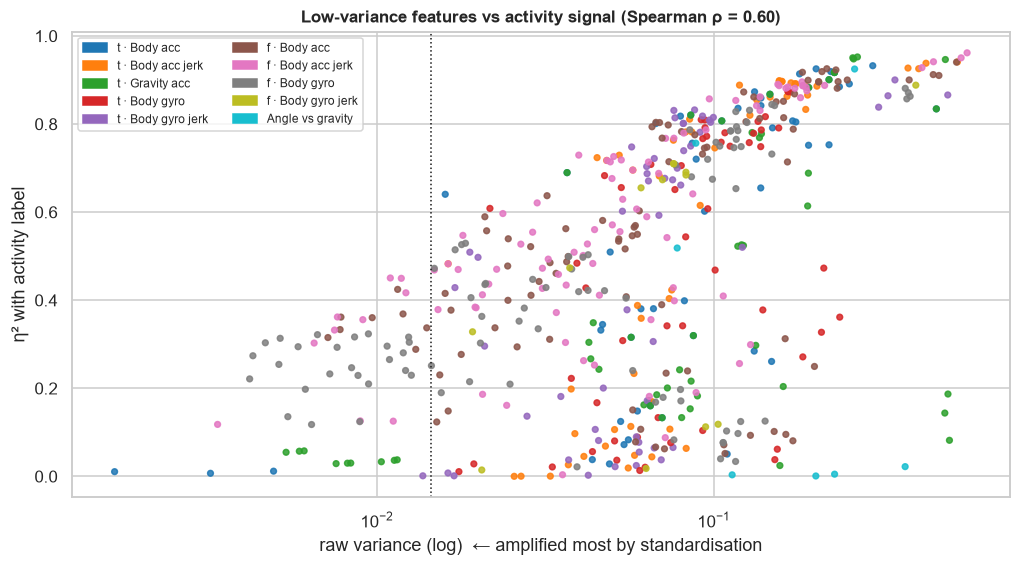

45 features have η² < 0.05 (activity explains <5% of their variance): {'arCoeff': 14, 'mean': 12, 'angle': 4, 'maxInds': 3, 'std': 2, 'mad': 2, 'iqr': 2, 'correlation': 2, 'entropy': 1, 'skewness': 1, 'kurtosis': 1, 'meanFreq': 1}


In [29]:
def eta_squared(X: pd.DataFrame, labels: pd.Series) -> pd.Series:
    Xv = X.to_numpy()
    grand = Xv.mean(axis=0)
    ss_total = ((Xv - grand) ** 2).sum(axis=0)
    ss_between = np.zeros(Xv.shape[1])
    for k in pd.unique(labels):
        mask = (labels == k).to_numpy()
        ss_between += mask.sum() * (Xv[mask].mean(axis=0) - grand) ** 2
    return pd.Series(ss_between / ss_total, index=X.columns)


eta2 = eta_squared(X_train, y_train)
amplification = 1 / shape["std"]
rho, _ = spearmanr(shape["variance"], eta2)

low_var = shape["variance"] <= shape["variance"].quantile(0.10)
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.scatter(shape["variance"], eta2, s=14, c=[GROUP_COLORS[gname] for gname in group_of], alpha=0.85)
ax.set_xscale("log")
ax.axvline(shape["variance"].quantile(0.10), ls=":", color="k", lw=1)
ax.set(xlabel="raw variance (log)  ← amplified most by standardisation", ylabel="η² with activity label",
       title=f"Low-variance features vs activity signal (Spearman ρ = {rho:.2f})")
ax.legend(handles=[Patch(color=GROUP_COLORS[gname], label=gname) for gname in GROUP_ORDER], fontsize=8,
          ncol=2, loc="upper left")
plt.show()

pd.DataFrame({
    "median η²": [eta2[low_var].median(), eta2[~low_var].median()],
    "% with η² < 0.2": [(eta2[low_var] < 0.2).mean() * 100, (eta2[~low_var] < 0.2).mean() * 100],
    "median amplification (1/σ)": [amplification[low_var].median(), amplification[~low_var].median()],
}, index=["lowest-variance 10% of features", "other 90%"]).round(3)

near_zero = eta2[eta2 < 0.05].index
print(f"{len(near_zero)} features have η² < 0.05 (activity explains <5% of their variance):",
      meta.loc[near_zero, "statistic"].value_counts().to_dict())

In [30]:
print("Most amplified features:")
pd.DataFrame({"raw σ": shape["std"], "amplification 1/σ": amplification, "η² activity": eta2,
              "group": group_of}).nlargest(10, "amplification 1/σ").round(3)

Most amplified features:


,raw σ,amplification 1/σ,η² activity,group
tBodyAcc-mean()-Y,0.041,24.503,0.011,t · Body acc
tBodyAcc-mean()-Z,0.057,17.657,0.007,t · Body acc
"fBodyAccJerk-bandsEnergy()-57,64-X",0.058,17.233,0.118,f · Body acc jerk
"fBodyGyro-bandsEnergy()-33,40-Y",0.065,15.444,0.221,f · Body gyro
"fBodyGyro-bandsEnergy()-33,40-Z",0.065,15.274,0.274,f · Body gyro
"fBodyGyro-bandsEnergy()-33,48-Z",0.068,14.639,0.303,f · Body gyro
tBodyAcc-mean()-X,0.070,14.233,0.012,t · Body acc
"fBodyGyro-bandsEnergy()-33,48-Y",0.072,13.977,0.254,f · Body gyro
"fBodyGyro-bandsEnergy()-25,48-Z",0.072,13.914,0.314,f · Body gyro
tGravityAcc-iqr()-X,0.073,13.637,0.055,t · Gravity acc


**Standardisation amplifies near-noise features**
* Raw variance and activity signal are positively related (Spearman ρ = 0.60). The lowest-variance 10 % of features have median η² = 0.25, compared with 0.56 for the rest, and they are amplified about 11× (median), against 3.6× for the rest.
* The most amplified features are the worst offenders. `tBodyAcc-mean()` X/Y/Z are scaled up 14–25× and have **η² ≈ 0.01**: body acceleration is gravity-removed, so its window mean is near zero for every activity. The same holds for the `mean()` of acceleration jerk, gyroscope and gyroscope jerk (η² ≤ 0.03).
* Forty-five features have η² < 0.05, mostly `arCoeff` (14), body-signal `mean()` (12) and four of the angle features. The four angles are those between gravity and the mean body, jerk or gyro vector, which are angles to a near-zero vector. After standardisation these weigh as much as the most informative features, and their heavy tails become values as large as ±25 σ (§6.1).
* **Caveat:** η² is a univariate, label-based screen. It flags *candidates* for removal; whether removing them helps should be confirmed inside cross-validation.

### 6.3 Relative weighting of the physical groups
For Euclidean-distance and variance-based methods, the expected squared distance between two random windows is 2 × Σ variances. So a group's **share of the total variance is its share of the distance** — i.e. its effective weight.
* **Raw:** weight ∝ the group's summed variance.
* **Standardised:** every feature has variance 1, so weight ∝ the number of features in the group.
* **Duplicate removal / correlation filter:** changes the feature counts, and therefore the weights.

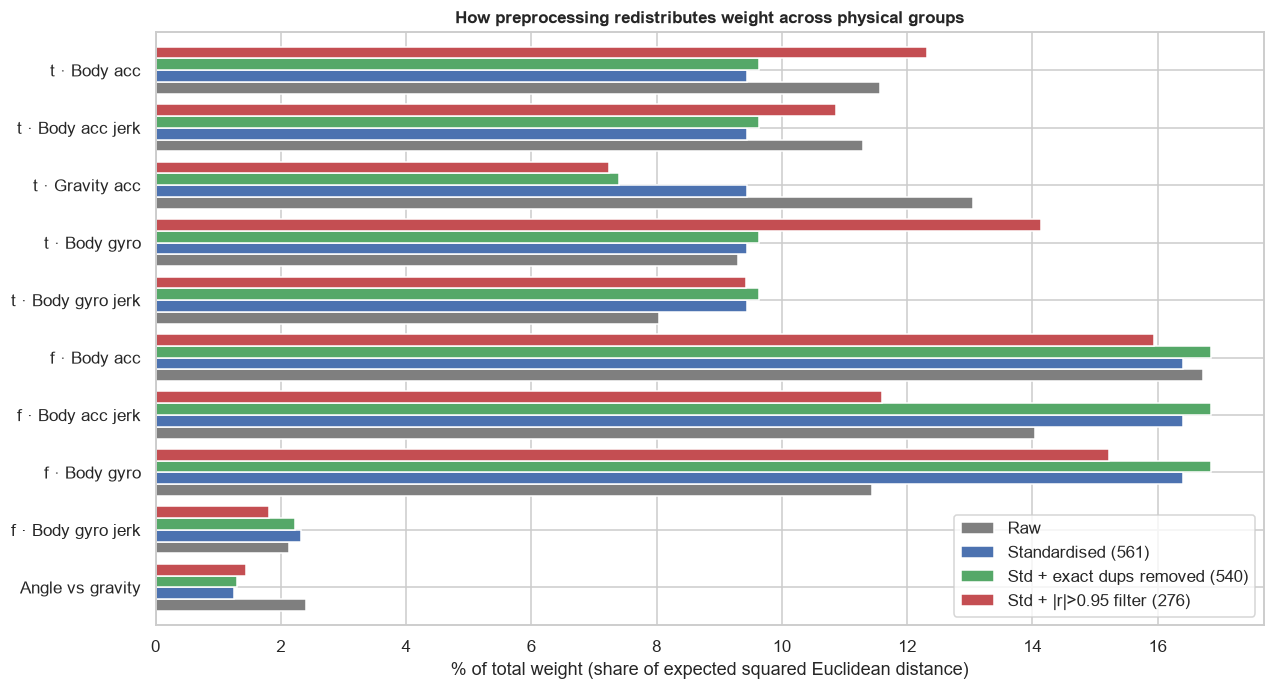

,Raw,Standardised (561),Std + exact dups removed (540),Std + |r|>0.95 filter (276)
group,,,,
t · Body acc,11.6,9.4,9.6,12.3
t · Body acc jerk,11.3,9.4,9.6,10.9
t · Gravity acc,13.1,9.4,7.4,7.2
t · Body gyro,9.3,9.4,9.6,14.1
t · Body gyro jerk,8.0,9.4,9.6,9.4
f · Body acc,16.7,16.4,16.9,15.9
f · Body acc jerk,14.0,16.4,16.9,11.6
f · Body gyro,11.4,16.4,16.9,15.2
f · Body gyro jerk,2.1,2.3,2.2,1.8


In [31]:
def weight_share(weights: pd.Series, by: pd.Series, order=None) -> pd.Series:
    out = weights.groupby(by.loc[weights.index].astype(str)).sum() / weights.sum() * 100
    return out.reindex(order) if order is not None else out


ones = lambda cols: pd.Series(1.0, index=cols)
schemes = {
    "Raw": shape["variance"],
    "Standardised (561)": ones(feature_names),
    f"Std + exact dups removed ({len(keep_dedup)})": ones(keep_dedup),
    f"Std + |r|>0.95 filter ({len(kept_095)})": ones(kept_095),
}
shares = pd.DataFrame({k: weight_share(w, meta["group"], GROUP_ORDER) for k, w in schemes.items()})

fig, ax = plt.subplots(figsize=(13, 7))
shares.iloc[::-1].plot.barh(ax=ax, width=0.82, color=["#7f7f7f", "#4c72b0", "#55a868", "#c44e52"])
ax.set(xlabel="% of total weight (share of expected squared Euclidean distance)", ylabel="",
       title="How preprocessing redistributes weight across physical groups")
ax.legend(loc="lower right")
plt.show()
shares.round(1)

In [32]:
by_domain = pd.DataFrame({k: weight_share(w, meta["domain"], ["Time", "Frequency", "Angle"]) for k, w in schemes.items()})
by_sensor = pd.DataFrame({k: weight_share(w, meta["sensor"], ["accelerometer", "gyroscope", "acc+gyro"]) for k, w in schemes.items()})
by_component = pd.DataFrame({k: weight_share(w, meta["component"], ["body", "gravity", "angle vs gravity"]) for k, w in schemes.items()})
pd.concat({"domain": by_domain, "sensor": by_sensor, "component": by_component}).round(1)

Raw  Standardised (561)  Std + exact dups removed (540)  Std + |r|>0.95 filter (276)
domain    Time              53.3                47.2                            45.9                         54.0
          Frequency         44.3                51.5                            52.8                         44.6
          Angle              2.4                 1.2                             1.3                          1.4
sensor    accelerometer     68.0                62.0                            61.3                         58.7
          gyroscope         30.9                37.6                            38.3                         40.6
          acc+gyro           1.1                 0.4                             0.4                          0.7
component body              84.5                89.3                            91.3                         91.3
          gravity           13.1                 9.4                             7.4                          7.2
          angle vs gravity   2.4                 1.2                             1.3                          1.4

**How the relative weighting shifts**
* **Raw → standardised:**
  * **Gravity** falls from 13.1 % to 9.4 % and **angle** halves (2.4 % → 1.2 %). These high-variance orientation features lose their raw advantage.
  * **Frequency-domain gyroscope** rises from 11.4 % to 16.4 %, because its many low-variance band energies now count fully.
  * By domain, the balance flips from time-heavy (53 % vs 44 %) to frequency-heavy (47 % vs 52 %). By sensor, the gyroscope rises from 31 % to 38 %.
* **Removing exact duplicates** cuts gravity further, to 7.4 %, and leaves the other groups almost unchanged (+0.2–0.5 pp each).
* **The |r| > 0.95 filter** removes most from the most redundant groups, so weight moves back toward the time domain (54 %): frequency acc-jerk falls to 11.6 %, and time-domain gyro rises to 14.1 %.
* **Takeaway:** standardisation does not make the physical groups equally important. It makes each group count in proportion to its number of features, and that count was set by how many statistics the dataset authors chose to compute. Correlation filtering partly corrects this by collapsing near-copies.

### 6.4 Effect on the principal components
PCA is the clearest view of how preprocessing changes the geometry the model sees. Note that PCA on raw data is dominated by whichever features happen to have the largest variance.

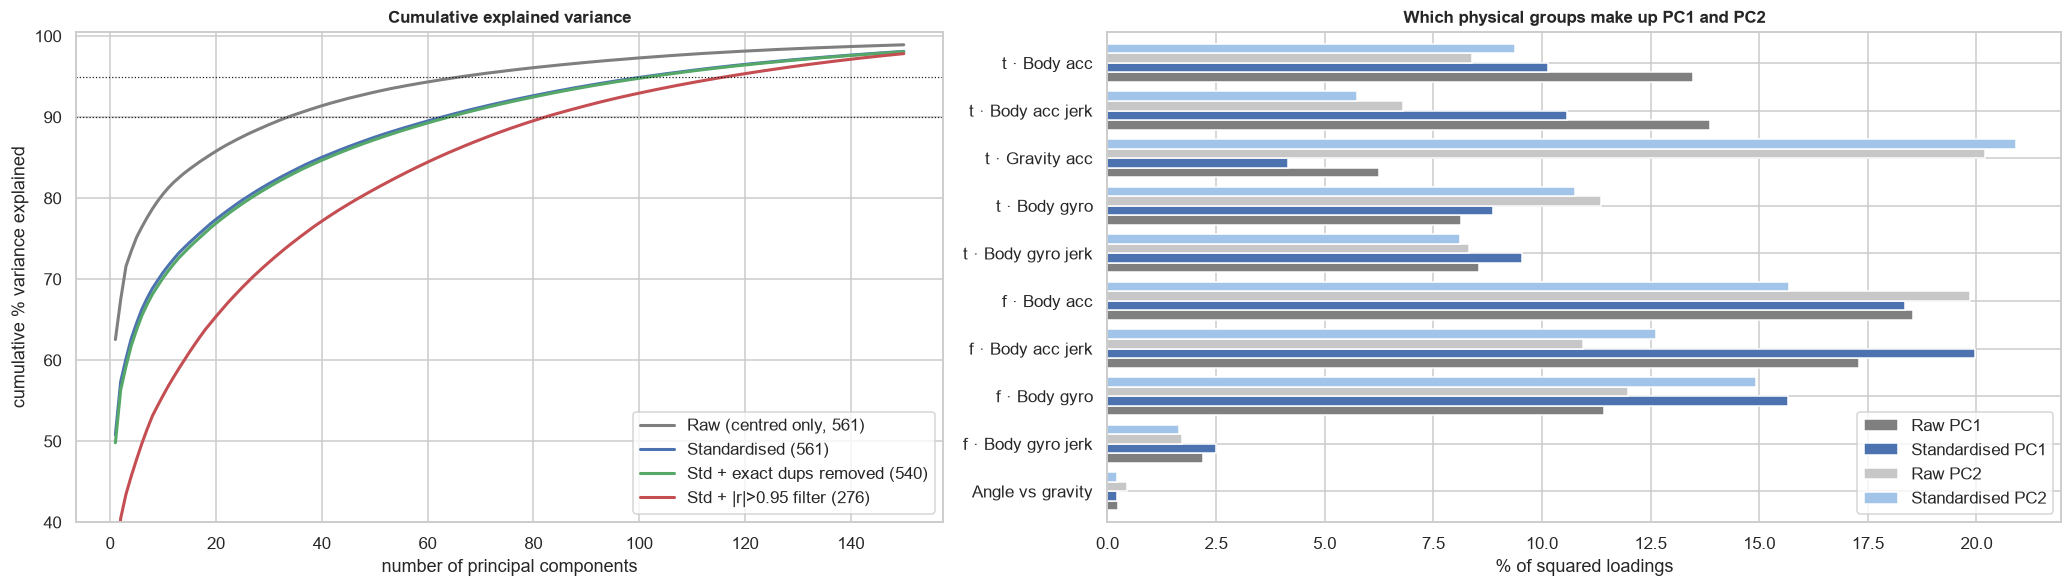

,components for 80% variance,components for 90% variance,components for 95% variance,components for 99% variance,PC1 % variance
"Raw (centred only, 561)",10,34,67,155,62.6
Standardised (561),26,63,102,179,50.8
Std + exact dups removed (540),27,64,103,179,49.8
Std + |r|>0.95 filter (276),47,83,117,176,32.7


In [33]:
variants = {
    "Raw (centred only, 561)": X_train,
    "Standardised (561)": Xs_train,
    f"Std + exact dups removed ({len(keep_dedup)})": Xs_train[keep_dedup],
    f"Std + |r|>0.95 filter ({len(kept_095)})": Xs_train[kept_095],
}
pcas = {name: PCA(svd_solver="full").fit(data) for name, data in variants.items()}

targets = [0.80, 0.90, 0.95, 0.99]
pca_table = pd.DataFrame({name: [int(np.searchsorted(np.cumsum(p.explained_variance_ratio_), t) + 1) for t in targets]
                          for name, p in pcas.items()},
                         index=[f"components for {int(t * 100)}% variance" for t in targets]).T
pca_table["PC1 % variance"] = [round(p.explained_variance_ratio_[0] * 100, 1) for p in pcas.values()]

fig, axes = plt.subplots(1, 2, figsize=(19, 5.5), gridspec_kw={"width_ratios": [1, 1.1]})
for (name, p), c in zip(pcas.items(), ["#7f7f7f", "#4c72b0", "#55a868", "#c44e52"]):
    axes[0].plot(np.arange(1, 151), np.cumsum(p.explained_variance_ratio_)[:150] * 100, label=name, color=c, lw=2)
for t in targets[1:3]:
    axes[0].axhline(t * 100, ls=":", color="k", lw=0.8)
axes[0].set(xlabel="number of principal components", ylabel="cumulative % variance explained",
            title="Cumulative explained variance", ylim=(40, 100.5))
axes[0].legend(loc="lower right")

pc1 = pd.DataFrame({
    "Raw PC1": weight_share(pd.Series(pcas["Raw (centred only, 561)"].components_[0] ** 2, index=feature_names), meta["group"], GROUP_ORDER),
    "Standardised PC1": weight_share(pd.Series(pcas["Standardised (561)"].components_[0] ** 2, index=feature_names), meta["group"], GROUP_ORDER),
    "Raw PC2": weight_share(pd.Series(pcas["Raw (centred only, 561)"].components_[1] ** 2, index=feature_names), meta["group"], GROUP_ORDER),
    "Standardised PC2": weight_share(pd.Series(pcas["Standardised (561)"].components_[1] ** 2, index=feature_names), meta["group"], GROUP_ORDER),
})
pc1.iloc[::-1].plot.barh(ax=axes[1], width=0.8, color=["#7f7f7f", "#4c72b0", "#c7c7c7", "#a1c4e8"])
axes[1].set(xlabel="% of squared loadings", ylabel="", title="Which physical groups make up PC1 and PC2")
plt.tight_layout()
plt.show()
pca_table

**What PCA reveals**
* **Raw data looks more compressible than it is.** 34 components reach 90 % of the variance, against 63 after standardisation, because a few high-variance features dominate the raw covariance. The standardised count is the fairer measure of dimensionality.
* **One "movement intensity" factor dominates.** PC1 explains 51 % of standardised variance, and its loadings are spread across every body-motion group. PC2 is led by **gravity** (≈ 20 % of its loadings in both versions), i.e. **orientation/posture**. This matches the static/dynamic and laying/upright splits seen in §3.2.
* **Exact duplicate removal barely changes the geometry** (102 → 103 components for 95 %).
* **The 0.95 filter halves the features but keeps most independent directions.** PC1 falls from 51 % to 33 % because many near-copies of "intensity" are gone, and 95 % of the variance now needs 117 of 276 components. The filtered set is far less redundant without collapsing.

### 6.5 How the train-fitted scaling transfers to the test subjects
If train and test came from the same distribution, standardised test features would have mean ≈ 0 and standard deviation ≈ 1. Departures show covariate shift between the 21 training subjects and the 9 test subjects.

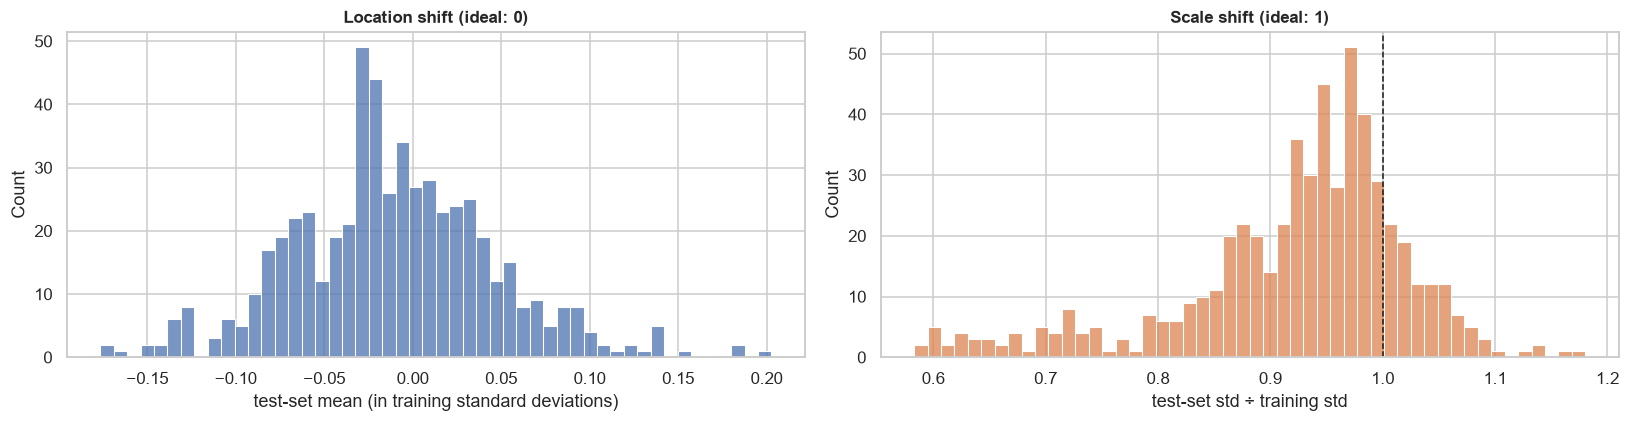

median |mean shift| (σ units)                  0.034
features with |mean shift| > 0.2σ                  1
features with std ratio outside [0.8, 1.25]       66
  of which energy / bandsEnergy                   57


,test mean (σ),test std ratio,group
"tBodyGyroJerk-correlation()-Y,Z",0.203,1.006,t · Body gyro jerk
"tGravityAcc-arCoeff()-X,1",0.186,1.034,t · Gravity acc
tBodyGyroMag-entropy(),0.182,0.954,t · Body gyro
tGravityAcc-sma(),-0.177,0.907,t · Gravity acc
"tGravityAcc-arCoeff()-X,2",-0.173,1.024,t · Gravity acc
"tBodyGyro-arCoeff()-X,3",-0.163,1.025,t · Body gyro
"tGravityAcc-arCoeff()-X,3",0.156,1.017,t · Gravity acc
tGravityAcc-energy()-Z,-0.152,0.892,t · Gravity acc


In [34]:
test_mean, test_std = Xs_test.mean(), Xs_test.std()
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.histplot(test_mean, bins=50, ax=axes[0], color="#4c72b0")
axes[0].set(xlabel="test-set mean (in training standard deviations)", title="Location shift (ideal: 0)")
sns.histplot(test_std, bins=50, ax=axes[1], color="#dd8452")
axes[1].axvline(1, color="k", ls="--", lw=1)
axes[1].set(xlabel="test-set std ÷ training std", title="Scale shift (ideal: 1)")
plt.tight_layout()
plt.show()

print(pd.Series(dtype=object, data={
    "median |mean shift| (σ units)": round(float(test_mean.abs().median()), 3),
    "features with |mean shift| > 0.2σ": int((test_mean.abs() > 0.2).sum()),
    "features with std ratio outside [0.8, 1.25]": int(((test_std < 0.8) | (test_std > 1.25)).sum()),
    "  of which energy / bandsEnergy": int(meta.loc[test_std.index[(test_std < 0.8) | (test_std > 1.25)], "statistic"]
                                            .isin(["energy", "bandsEnergy"]).sum()),
}).to_string())
pd.DataFrame({"test mean (σ)": test_mean, "test std ratio": test_std, "group": group_of}) \
    .reindex(test_mean.abs().sort_values(ascending=False).index).head(8).round(3)

**Train-fitted scaling transfers well, with one systematic difference**
* **Location:** test means are essentially centred (median |shift| 0.03 σ, largest 0.20 σ). No feature is badly mis-centred.
* **Scale:** the test set is systematically *narrower* (median std ratio 0.94). The 66 features below 0.8 are mostly frequency-domain `energy`/`bandsEnergy` features (57 of 66), and none are above 1.25. These heavy-tailed energy features depend on how vigorously each person moves, so the 9 test subjects simply cover a smaller range than the 21 training subjects.
* **Implication:** between-subject variation is real and concentrated in energy features. Validation should hold out whole subjects, and a log or Yeo–Johnson transform of the energy features would reduce sensitivity to a few vigorous subjects.

## 7. Summary and recommended preprocessing

In [35]:
summary = pd.Series({
    "Windows (train / test)": f"{len(X_train):,} / {len(X_test):,}",
    "Subjects (train / test), overlap": f"{subj_train.nunique()} / {subj_test.nunique()}, none",
    "Missing / non-finite values": int(X_all.isna().to_numpy().sum() + np.isinf(arr_all).sum()),
    "Duplicate rows (within or across splits)": int(h_train.duplicated().sum() + h_test.duplicated().sum() + h_test.isin(set(h_train)).sum()),
    "Duplicate feature names (bandsEnergy X/Y/Z)": f"{len(dup_names)} names × 3 = {int(dup_names.sum())} columns, renamed",
    "Value-identical columns": f"{len(dup_groups)} groups, {len(exact_drop)} redundant",
    "Zero-variance features": int((const["variance"] == 0).sum()),
    "Discrete features (≤ 50 distinct values)": int((const["n_unique"] <= 50).sum()),
    "Value range": f"[{arr_all.min():.0f}, {arr_all.max():.0f}]",
    "Cells outside 1.5×IQR fences (train)": f"{out_mask.to_numpy().mean() * 100:.1f}%",
    "Features with |skew| > 1": int((shape["skewness"].abs() > 1).sum()),
    "Variance ratio max / min": f"{shape['variance'].max() / shape['variance'].min():.0f}×",
    "Feature pairs with |r| ≥ 0.95": int((pair_r >= 0.95).sum()),
    "Features kept by |r| > 0.95 filter": f"{len(kept_095)} of 561",
    "PCA components for 95% (standardised)": int(pca_table.loc["Standardised (561)", "components for 95% variance"]),
    "Median |test mean shift| after scaling": f"{test_mean.abs().median():.2f} σ",
}).to_frame("result")
summary

,result
Windows (train / test),"7,352 / 2,947"
"Subjects (train / test), overlap","21 / 9, none"
Missing / non-finite values,0
Duplicate rows (within or across splits),0
Duplicate feature names (bandsEnergy X/Y/Z),"42 names × 3 = 126 columns, renamed"
Value-identical columns,"19 groups, 21 redundant"
Zero-variance features,0
Discrete features (≤ 50 distinct values),11
Value range,"[-1, 1]"
Cells outside 1.5×IQR fences (train),4.0%


### Key findings
1. **Clean data.** There are no missing or non-finite values, no duplicate windows, no constant features, and no subject overlap between train and test. Classes are reasonably balanced (13–19 % each). All values are already bounded in [−1, 1].
2. **Two labelling problems in the source files:**
   * 126 `bandsEnergy` columns share 42 names (they are the X/Y/Z axes).
   * 21 columns are exact copies: `tGravityAccMag` ≡ `tBodyAccMag`, which is a source bug, and `Mag-sma()` ≡ `Mag-mean()`, which holds by definition.
3. **Extremes and saturation are signal, not noise.** 80 % of outliers come from dynamic windows, and the pile-ups at −1 are floor effects from static postures.
4. **Distributions are skewed and bimodal.** About half the features have |skew| > 1, especially frequency-domain energies, and most features mix static and dynamic modes.
5. **The feature set is highly redundant.** 70 % of features have a near-twin at |r| ≥ 0.95, and a 0.95 filter halves the set (561 → 276). Spread statistics (`std`/`mad`/`iqr`) and time/frequency energies (Parseval's theorem) are the main overlaps.
6. **Two main axes of information:** movement intensity (all body-motion groups, PC1) and posture/orientation (gravity and angle features, PC2).
7. **Standardisation changes the relative weights.** It equalises features rather than physical groups, which raises gyroscope and frequency-domain weight. It also amplifies a set of near-zero-information features, such as body-signal `mean()`, by up to 25×.

### Recommended preprocessing decisions

| # | Decision | Why (evidence in this notebook) |
|---|---|---|
| 1 | **Keep all rows.** No imputation, row de-duplication, outlier removal or clipping. | 0 missing and 0 duplicate rows; values bounded; extremes come from dynamic activities (§2.5). |
| 2 | **Rename the 126 `bandsEnergy` columns** with `-X/-Y/-Z` suffixes. | Same-named columns hold different data (§2.3). Unique names are needed by pandas, sklearn and any feature-importance work. |
| 3 | **Drop the 21 value-identical columns** (561 → 540). | Lossless (§2.3); removes the `tGravityAccMag` bug and stops gravity being double-counted (§6.3). |
| 4 | **Standardise with `StandardScaler` fitted on training data only**, inside each CV fold, for scale-sensitive models (k-NN, SVM, logistic regression, PCA, neural networks). Not needed for tree ensembles. | Variances differ 339× (§3.3). Standardisation is linear, so correlations and shapes are unchanged (§6). The train-fitted scaler transfers well (§6.5). |
| 5 | **Flag low-signal features as removal candidates and test the removal in CV:** body-signal `mean()` (12) and the 4 `angle()` features built on body means. | η² ≈ 0.00–0.03, physically ≈ 0 by construction, and amplified up to 25× by scaling (§6.2). |
| 6 | **For linear or distance-based models, or for interpretability: apply a \|r\| > 0.95 correlation filter fitted on train** (→ 276 features), or use PCA (~100 components for 95 %). Treat the threshold as a hyperparameter. | 2,281 pairs ≥ 0.95; `std`/`mad`/`iqr` and time/frequency energies are near-copies (§4). |
| 7 | **Optional:** Yeo–Johnson or log transform of `energy`/`bandsEnergy` features for models that assume roughly Gaussian inputs (LDA, Gaussian NB). | Median skew 2–3, kurtosis up to 19 (§3.1); main source of train/test scale shift (§6.5). |
| 8 | **Validate with subject-wise splits** (`GroupKFold` on `subject`), never random row splits. | 50 % window overlap between consecutive rows; between-subject differences in energy features (§6.5). |

The cell below implements decisions 2–4 as a leakage-safe sklearn pipeline (decision 2 happens at load time). Decisions 5–7 are optional steps to compare during modelling.

In [36]:
# The recommended baseline, as a leakage-safe sklearn pipeline: put it in front of any model and fit it
# inside cross-validation so the scaler only ever sees training folds.
baseline_preprocess = Pipeline([
    ("drop_exact_duplicates", ColumnTransformer([("keep", "passthrough", keep_dedup)], remainder="drop")),
    ("standardise", StandardScaler()),
])
Xp_train = baseline_preprocess.fit_transform(X_train)
Xp_test = baseline_preprocess.transform(X_test)
print("Preprocessed train:", Xp_train.shape, " test:", Xp_test.shape)

Preprocessed train: (7352, 540)  test: (2947, 540)


In [37]:
# Per-feature audit table for the rest of the team
audit = meta.drop(columns=["col"]).copy()
audit["group"] = group_of
audit = audit.join(shape[["mean", "std", "variance", "skewness", "excess kurtosis", "bimodality coef"]])
audit = audit.join(extreme[["% at -1", "% at +1", "% IQR outliers"]])
audit["n_unique"] = const["n_unique"]
audit["max |r| with another feature"] = max_abs_r
audit["exact duplicate of"] = pd.Series(exact_dup_of)
audit["keep: exact dedup"] = audit.index.isin(keep_dedup)
audit["keep: |r|>0.95 filter"] = audit.index.isin(kept_095)
audit["eta2 activity"] = eta2
audit["test mean shift (σ)"] = test_mean
audit.index.name = "feature"

if SAVE_OUTPUTS:
    OUTPUT_DIR.mkdir(exist_ok=True)
    audit.to_csv(OUTPUT_DIR / "task1_feature_audit.csv")
    print("Saved", OUTPUT_DIR / "task1_feature_audit.csv")
audit.head()

Saved task1_outputs\task1_feature_audit.csv


,raw_name,domain,signal,sensor,component,jerk,magnitude,axis,statistic,group,mean,std,variance,skewness,excess kurtosis,bimodality coef,% at -1,% at +1,% IQR outliers,n_unique,max |r| with another feature,exact duplicate of,keep: exact dedup,keep: |r|>0.95 filter,eta2 activity,test mean shift (σ)
feature,,,,,,,,,,,,,,,,,,,,,,,,,,
tBodyAcc-mean()-X,tBodyAcc-mean()-X,Time,tBodyAcc,accelerometer,body,False,False,X,mean,t · Body acc,0.2745,0.0703,0.0049,-3.4483,50.9114,0.2391,0.0136,0.0136,24.4151,7347,0.5443,NaN,True,True,0.0119,-0.0070
tBodyAcc-mean()-Y,tBodyAcc-mean()-Y,Time,tBodyAcc,accelerometer,body,False,False,Y,mean,t · Body acc,-0.0177,0.0408,0.0017,-0.4030,172.4857,0.0066,0.0136,0.0136,15.2612,7352,0.1952,NaN,True,True,0.0107,-0.0041
tBodyAcc-mean()-Z,tBodyAcc-mean()-Z,Time,tBodyAcc,accelerometer,body,False,False,Z,mean,t · Body acc,-0.1091,0.0566,0.0032,1.7845,85.9750,0.0470,0.0136,0.0136,16.0501,7349,0.2935,NaN,True,True,0.0070,0.0133
tBodyAcc-std()-X,tBodyAcc-std()-X,Time,tBodyAcc,accelerometer,body,False,False,X,std,t · Body acc,-0.6054,0.4487,0.2014,0.6774,-0.8656,0.6831,0.0136,0.0136,0.0272,7349,0.9986,NaN,True,True,0.9254,-0.0183
tBodyAcc-std()-Y,tBodyAcc-std()-Y,Time,tBodyAcc,accelerometer,body,False,False,Y,std,t · Body acc,-0.5109,0.5026,0.2527,0.4059,-1.4527,0.7522,0.0000,0.0000,0.0000,7351,0.9978,NaN,True,True,0.8912,0.0052
